# Thu thập và khám phá dữ liệu TMDB + IMDb

**Cập nhật ngày 17/11/2026 theo bốn câu hỏi đã chốt.** CSV đầu vào là bản nhóm tải ngày 05/11/2026.
Notebook kiểm tra cấu trúc, chất lượng, phân phối và các mối liên hệ sơ bộ theo mục 3.2 của
[đề bài](../doc/CSC17104_2026_Final_Project.pdf).

Các bảng chất lượng đếm số dòng trong CSV gốc. Phần quan hệ có mẫu riêng cho từng câu hỏi, kèm điều kiện
và số dòng trước, sau mỗi bước lọc. Phạm vi câu hỏi và người phụ trách được ghi tại
[QUESTIONS.md](../doc/QUESTIONS.md).

Chọn kernel **Python (movies-dataset)** và chạy lại toàn bộ notebook từ đầu. Notebook đọc CSV cục bộ,
thực hiện chuyển kiểu và lọc trong bộ nhớ. Các ghi chú và mã có hỗ trợ của Codex được ghi trong
[LLM_USAGE.md](../LLM_USAGE.md). Theo mục 6 của đề, nhóm cần hiểu mã, kiểm chứng kết quả
và tự viết phần phân tích, câu trả lời, reflection dùng trong bài nộp.

## 1. Nguồn và bối cảnh

- **Chủ đề.** Bộ dữ liệu mô tả các tác phẩm trong danh mục phim TMDB được liên kết với dữ liệu IMDb.
  Dữ liệu bao gồm đặc điểm tác phẩm như thể loại, ngôn ngữ, thời lượng và ngày phát hành, cùng ngân sách, doanh thu,
  điểm đánh giá và số lượt chấm. Nhóm dùng dữ liệu để tìm hiểu mối liên hệ giữa đặc điểm phim, kết quả tài chính
  và đánh giá của khán giả trên hai nền tảng.
- **Nguồn gốc.** Nhóm sử dụng file CSV trong bộ [TMDB + IMDB Merged Movies Dataset](https://www.kaggle.com/datasets/ggtejas/tmdb-imdb-merged-movies-dataset/data)
  do **Tejas Garg (`ggtejas`)** công bố trên Kaggle. Trong phần mô tả, tác giả dẫn hai nguồn dữ liệu.

  - **TMDB.** Tác giả lấy thông tin phim như tên, ngày phát hành và doanh thu từ [bộ dữ liệu TMDB do `asaniczka` đăng trên Kaggle](https://www.kaggle.com/datasets/asaniczka/tmdb-movies-dataset-2023-930k-movies).
  - **IMDb.** Tác giả sử dụng [IMDb Non-Commercial Datasets](https://developer.imdb.com/non-commercial-datasets/)
    do IMDb cung cấp để bổ sung thông tin như đạo diễn, biên kịch, diễn viên, điểm và số lượt chấm trên IMDb.

  Phiên bản đầu tiên trên Kaggle (**v1**) ghi ngày **13/11/2024**. Nhóm tải bản **v578** ngày **05/11/2026**,
  cùng ngày bản này được cập nhật trên Kaggle. SHA-256 của CSV nhóm dùng khớp với CSV tải lại từ v578.
- **Giấy phép:** [CC BY-NC-SA 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/) của bản tổng hợp;
  ghi nguồn và các thay đổi, sử dụng phi thương mại, tuân thủ điều kiện chia sẻ tương tự.
  Đối chiếu thêm điều kiện của [IMDb](https://developer.imdb.com/non-commercial-datasets/)
  và [TMDB](https://developer.themoviedb.org/docs/faq); nhãn của bản tổng hợp không thay thế điều kiện nguồn.
- **Cách thu thập dữ liệu (Collection method).** Nhóm tải CSV đã được tác giả tổng hợp từ hai nguồn có sẵn.
  Tác giả chưa mô tả chi tiết quy tắc ghép dữ liệu hay cách xử lý mã trùng.

  - **Phạm vi tác phẩm.** Phạm vi là các tác phẩm có trong bản ghép v578. Mức độ bao phủ toàn bộ
    danh mục TMDB và IMDb chưa được xác nhận. CSV thiếu trường `titleType` để phân biệt chắc chắn phim điện ảnh,
    phim ngắn và tác phẩm truyền hình.
  - **Thời kỳ dữ liệu.** Trong CSV, ngày phát hành ghi nhận nằm từ **09/12/1874** đến **13/10/2029**.
    Khoảng này có cả ngày sau ngày nhóm tải. Tác giả chưa công bố thời điểm trích xuất từng nguồn,
    nên thời điểm ghi nhận điểm và lượt chấm của mỗi nền tảng chưa được xác minh.
  - **Giới hạn và khả năng sai lệch.** Các dòng trong CSV có thể thiên về những tác phẩm có thông tin ở cả hai
    nền tảng. CSV thiếu đơn vị tiền tệ theo từng dòng và chưa có xác nhận về cách chuẩn hóa hay điều chỉnh lạm phát.
    Để tính lợi nhuận thực còn cần các khoản chi phí và khoản phân chia doanh thu ngoài những gì CSV ghi nhận.
- **Lý do chọn:** Chủ đề phim ảnh gần gũi. Dữ liệu có thông tin tài chính, thuộc tính đa nhãn và điểm từ hai nền tảng,
  phù hợp tìm hiểu các khác biệt theo nhóm và theo thời gian.

Tài liệu IMDb định nghĩa `averageRating` là điểm trung bình có trọng số và `numVotes` là số lượt chấm;
`tconst` là mã tác phẩm. Metadata nguồn là mô tả của người công bố, không chứng minh chất lượng từng dòng dữ liệu.

Bốn câu hỏi xác định trọng tâm khám phá như sau.

| Câu hỏi | Các cột cần khám phá sâu | Thông tin cần chuẩn bị |
| --- | --- | --- |
| Q1. IMDb và TMDB chấm lệch nhau thế nào? | `vote_average`, `vote_count`, `averageRating`, `numVotes`, `genres`, `release_date` | Khoảng điểm và số lượt chấm, số cặp đủ điều kiện ở các ngưỡng và độ đầy đủ của thể loại. |
| Q2. Dự đoán điểm IMDb từ hồ sơ phim | `averageRating`, `runtime`, `genres`, `original_language`, `release_date` | Độ đầy đủ của đầu vào, phân phối mục tiêu trên phần trước 2020 và số phim trong hai khoảng thời gian. |
| Q3. Phim có ngày càng dài hơn? | `runtime`, `release_date`, `genres`, `original_language`, `status` | Số 0 và cực trị thời lượng, số tác phẩm từng giai đoạn và thành phần thể loại, ngôn ngữ. |
| Q4. Cùng mức ngân sách, thể loại nào có doanh thu cao hơn? | `budget`, `revenue`, `genres`, `release_date`, `original_language`, `status` | Số 0, cực trị tài chính, đơn vị tiền tệ, số mẫu trong các nhóm thể loại, ngân sách và giai đoạn. |

`id` và `tconst` dùng để kiểm tra mã phim cho cả bốn câu. Từ điển ở mục 2 tóm tắt đủ 29 cột.
Các biểu đồ tập trung vào những cột trong bảng này.

In [1]:
from pathlib import Path
import csv
import hashlib
import platform
import sys

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'environment.yml').is_file() and (p / 'data/raw').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Mở notebook từ thư mục repository hoặc notebooks/.')
RAW_PATH = ROOT / 'data/raw/TMDB  IMDB Movies Dataset.csv'
if not RAW_PATH.is_file():
    raise FileNotFoundError(f'Tải CSV theo README và đặt tại: {RAW_PATH}')
DOWNLOAD_DATE = pd.Timestamp('2026-11-05')
RANDOM_STATE = 42
pd.set_option('display.max_rows', 40)
pd.set_option('display.max_columns', 12)
sns.set_theme(style='whitegrid', font='DejaVu Sans')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 11, 'axes.labelsize': 10})
display(pd.Series({'Python': platform.python_version(), 'pandas': pd.__version__,
                   'numpy': np.__version__, 'matplotlib': matplotlib.__version__,
                   'seaborn': sns.__version__, 'executable': sys.executable}, name='Môi trường'))

def file_sha256(path):
    h = hashlib.sha256()
    with path.open('rb') as f:
        for block in iter(lambda: f.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

raw_sha256 = file_sha256(RAW_PATH)
print('SHA-256:', raw_sha256)
# Giữ nguyên chuỗi như NA/N/A/NULL nếu có; chỉ ô trống và ký hiệu IMDb \N là thiếu.
movies = pd.read_csv(RAW_PATH, low_memory=False, keep_default_na=False, na_values=['', r'\N'])
n = len(movies)
display(pd.Series({'dòng': n, 'cột': movies.shape[1], 'byte': RAW_PATH.stat().st_size,
                   'SHA-256': raw_sha256, 'ngày tải': str(DOWNLOAD_DATE.date())}, name='CSV cục bộ'))
display(movies[['id', 'tconst', 'title', 'release_date', 'budget', 'revenue']].head())

Python                                                  3.11.13
pandas                                                    2.2.3
numpy                                                     2.2.6
matplotlib                                               3.10.3
seaborn                                                  0.13.2
executable    C:\Users\maida\miniconda3\envs\movies-dataset\...
Name: Môi trường, dtype: object

SHA-256: f1c78500acd6a953492bdaa2413015b54baa082a213628e8ecd96be4e5dfe5f4


dòng                                                   443656
cột                                                        29
byte                                                282010663
SHA-256     f1c78500acd6a953492bdaa2413015b54baa082a213628...
ngày tải                                           2026-11-05
Name: CSV cục bộ, dtype: object

,id,tconst,title,release_date,budget,revenue
0,27205,tt1375666,Inception,2010-07-15,160000000,825532764
1,157336,tt0816692,Interstellar,2014-11-05,165000000,701729206
2,155,tt0468569,The Dark Knight,2008-07-16,185000000,1004558444
3,19995,tt0499549,Avatar,2009-12-15,237000000,2923706026
4,24428,tt0848228,The Avengers,2012-04-25,220000000,1518815515


## 2. Tổng quan về cấu trúc CSV và mã phim

Phần này kiểm tra số dòng, số cột, các dòng trống và mã phim xuất hiện nhiều lần. Một dòng CSV là một bộ thông tin sau khi ghép hai nguồn. Cùng một tác phẩm có thể có nhiều dòng.

Các ô code từ đây được thu gọn mặc định. Mỗi bảng hoặc hình đi cùng một đoạn giải thích ngắn. Bạn có thể bấm phần code đã thu gọn để xem cách tính, hoặc chạy lại toàn bộ notebook như bình thường.

### 2.1. File có dòng trống hoặc sai số ô không?

File có 29 cột nên một dòng đầy đủ cấu trúc có 29 vị trí, dù một vài ô có thể trống. Bảng đếm dòng CSV sau hàng tiêu đề. Văn bản xuống dòng trong một ô vẫn được tính trong cùng một dòng dữ liệu.

In [2]:
empty_records = 0
all_blank_records = 0
wrong_width_records = 0
csv_records = 0
with RAW_PATH.open(encoding='utf-8-sig', newline='') as f:
    reader = csv.reader(f)
    header = next(reader)
    for row in reader:
        csv_records += 1
        if not row:
            empty_records += 1
        else:
            all_blank_records += all(not value.strip() for value in row)
            wrong_width_records += len(row) != len(header)

missing = movies.isna().copy()
space_only = pd.Series(0, index=movies.columns, dtype='int64')
for col in movies.select_dtypes(include=['object', 'string']):
    blank = movies[col].str.fullmatch(r'\s+', na=False)
    space_only[col] = blank.sum()
    missing[col] |= blank

structure = pd.Series({
    'Tổng số dòng trong CSV, kể cả dòng trống': csv_records,
    'Dòng trống hoàn toàn': empty_records,
    'Dòng có ô nhưng tất cả ô đều trống': all_blank_records,
    f'Dòng có số ô khác {len(header)}': wrong_width_records,
    'Dòng thiếu tất cả giá trị sau khi đọc CSV': int(missing.all(axis=1).sum()),
    'Dòng giống hệt một dòng trước đó': int(movies.duplicated().sum()),
})
display(structure.to_frame('Số lượng'))

,Số lượng
"Tổng số dòng trong CSV, kể cả dòng trống",443656
Dòng trống hoàn toàn,0
Dòng có ô nhưng tất cả ô đều trống,0
Dòng có số ô khác 29,0
Dòng thiếu tất cả giá trị sau khi đọc CSV,0
Dòng giống hệt một dòng trước đó,0


Bảng có sáu phép kiểm tra riêng.

| Hàng kiểm tra | Cách đọc |
| --- | --- |
| Tổng số dòng trong CSV, kể cả dòng trống | Số dòng dữ liệu sau tiêu đề. |
| Dòng trống hoàn toàn | Dòng không có chữ hay dấu phân cách. |
| Dòng có ô nhưng tất cả ô đều trống | Các dấu phẩy vẫn chia thành ô, nhưng mọi ô đều trống hoặc chỉ có dấu cách. |
| Dòng có số ô khác 29 | Số ô đọc được khác số cột trong tiêu đề. Một ô trống vẫn được tính là một ô. |
| Dòng thiếu tất cả giá trị sau khi đọc CSV | Sau khi nhận diện ô trống và ký hiệu thiếu như `\N`, mọi ô trong dòng đều thiếu. |
| Dòng giống hệt một dòng trước đó | Số bản sao dư khi so toàn bộ 29 cột. |

Các phép kiểm tra có thể cùng đếm một dòng. Trên CSV này, năm phép kiểm tra vấn đề đều cho kết quả 0. Việc một dòng thiếu vài ô được xét riêng ở mục 5.

### 2.2. Mã phim có bị lặp không?

`id` là mã tác phẩm trên **TMDb**, còn `tconst` là mã trên **IMDb**. Bảng kiểm tra hai mã riêng biệt.

In [3]:
key_rows = []
for col in ['id', 'tconst']:
    known = movies.loc[~missing[col], col]
    key_rows.append([col, missing[col].sum(), known.nunique(), known.duplicated().sum(),
                     known.duplicated(keep=False).sum()])
key_audit = pd.DataFrame(key_rows, columns=['Cột mã', 'Dòng thiếu mã', 'Số mã khác nhau',
                                            'Dòng lặp sau lần đầu', 'Dòng có mã lặp'])
display(key_audit)

,Cột mã,Dòng thiếu mã,Số mã khác nhau,Dòng lặp sau lần đầu,Dòng có mã lặp
0,id,0,429762,13894,17372
1,tconst,0,426661,16995,18467


**Số mã khác nhau** là số mã riêng biệt xuất hiện trong CSV. **Dòng lặp sau lần đầu** bỏ qua lần đầu của mỗi mã rồi đếm các lần còn lại. **Dòng có mã lặp** tính cả lần đầu.

Ví dụ, mã xuất hiện 3 lần có 2 dòng lặp sau lần đầu và 3 dòng có mã lặp. Một dòng có thể được tính trong cả hàng `id` và hàng `tconst`, nên hai số dòng lặp phải được đọc riêng.

### 2.3. Hai mã được nối với nhau như thế nào?

Một mã TMDb có thể xuất hiện ở nhiều dòng nhưng vẫn chỉ đi với cùng một mã IMDb. Bảng dưới kiểm tra chiều nối đó và chiều ngược lại, đồng thời kiểm tra dạng của mã.

In [4]:
id_to_imdb = movies.groupby('id')['tconst'].nunique()
imdb_to_id = movies.groupby('tconst')['id'].nunique()
display(pd.Series({'Mã TMDB đi với nhiều mã IMDb': int(id_to_imdb.gt(1).sum()),
                   'Mã IMDb đi với nhiều mã TMDB': int(imdb_to_id.gt(1).sum()),
                   'Mã TMDB bằng 0 hoặc âm': int(movies.id.le(0).sum()),
                   'Mã IMDb sai dạng tt + chữ số': int((~movies.tconst.str.fullmatch(r'tt\d+', na=False)).sum())}))

Mã TMDB đi với nhiều mã IMDb       0
Mã IMDb đi với nhiều mã TMDB    1424
Mã TMDB bằng 0 hoặc âm             0
Mã IMDb sai dạng tt + chữ số       0
dtype: int64

Có **1.424 mã IMDb** đi với nhiều mã TMDb. Cần kiểm tra thông tin giữa các dòng theo cả hai chiều trước khi chọn cách gộp.

Hai bảng dưới xét riêng nhóm cùng mã TMDb và nhóm cùng mã IMDb. Bảng đầu ghi số nhóm mã lặp được kiểm tra. Bảng sau đếm có bao nhiêu nhóm khác nhau ở từng cột. Một ô có giá trị và một ô trống trong cùng nhóm cũng được tính là thông tin khác nhau.

Mỗi cột có số nhóm được kiểm tra khác nhau, nên cần đọc kết quả cùng bảng đầu.

In [5]:
conflicts_by_key = {}
repeated_key_groups = []
for key, platform in [('id', 'TMDb'), ('tconst', 'IMDb')]:
    repeated_rows = movies.loc[movies[key].notna() & movies[key].duplicated(keep=False)]
    repeated_key_groups.append([platform, key, repeated_rows[key].nunique(), len(repeated_rows)])
    conflicts_by_key[platform] = repeated_rows.groupby(key).nunique(dropna=False).gt(1).sum()

display(pd.DataFrame(repeated_key_groups, columns=[
    'Nền tảng', 'Cột mã', 'Số mã lặp được kiểm tra', 'Số dòng mang các mã này']))
conflict_counts = pd.DataFrame(conflicts_by_key).fillna(0).astype(int)
conflict_counts = conflict_counts.sort_values(['TMDb', 'IMDb'], ascending=False)
display(conflict_counts.rename(columns={
    'TMDb': 'Số mã TMDb có thông tin khác nhau',
    'IMDb': 'Số mã IMDb có thông tin khác nhau',
}).rename_axis('Cột được so sánh'))

,Nền tảng,Cột mã,Số mã lặp được kiểm tra,Số dòng mang các mã này
0,TMDb,id,3478,17372
1,IMDb,tconst,1472,18467


,Số mã TMDb có thông tin khác nhau,Số mã IMDb có thông tin khác nhau
Cột được so sánh,,
cast,3429,975
popularity,51,1334
release_date,39,1067
genres,37,1110
poster_path,35,1311
production_companies,22,804
spoken_languages,20,896
production_countries,20,834
runtime,14,844


Cách đọc ví dụ trong bảng trên như sau.

| Cột | Cùng mã TMDb | Cùng mã IMDb |
| --- | --- | --- |
| `cast` | 3.429 nhóm khác danh sách diễn viên | 975 nhóm khác danh sách diễn viên |
| `release_date` | 39 nhóm khác ngày phát hành | 1.067 nhóm khác ngày phát hành |
| `budget` | 2 nhóm khác ngân sách | 199 nhóm khác ngân sách |

Bảng kiểm tra **3.478 mã TMDb lặp** và **1.472 mã IMDb lặp**. Khi cùng mã IMDb nối với nhiều mã TMDb, thông tin lấy từ TMDb như tên phim, ngày phát hành hoặc ngân sách có thể khác nhau giữa các dòng. Các cột IMDb `averageRating`, `numVotes`, `directors` và `writers` hiện nhất quán trong các nhóm cùng mã IMDb. Muốn gộp, nhóm cần đối chiếu xem các dòng có thực sự mô tả cùng tác phẩm và chọn cách xử lý xung đột.

Bảng tiếp theo liệt kê 10 mã IMDb xuất hiện nhiều dòng nhất. `Số mã TMDB khác nhau` cho biết mỗi mã IMDb đang nối với bao nhiêu mục trên TMDb.

In [6]:
display(movies.groupby('tconst').agg(so_dong=('id', 'size'), so_id=('id', 'nunique'))
        .sort_values('so_dong', ascending=False).head(10)
        .rename(columns={'so_dong': 'Số dòng có mã IMDb này', 'so_id': 'Số mã TMDB khác nhau'}))

,Số dòng có mã IMDb này,Số mã TMDB khác nhau
tconst,,
tt32094375,3996,148
tt26900526,1892,86
tt1757779,810,45
tt13904644,702,54
tt22075376,406,29
tt29703523,261,29
tt0813980,247,19
tt5719786,238,34
tt2705436,193,17


### 2.4. Mẫu dùng cho các mối liên hệ sơ bộ

Giữ những dòng có **cả hai mã đều chỉ xuất hiện một lần trong toàn bộ CSV**. Cách này loại toàn bộ các nhóm mã lặp, kể cả các nhóm chỉ khác diễn viên, vì quy tắc gộp chưa được xác định. Mẫu còn lại có thể khác thành phần của CSV gốc, nên bảng dưới đối chiếu một số đặc điểm của hai mẫu.

In [7]:
unique_keys = (~movies.id.duplicated(keep=False) & ~movies.tconst.duplicated(keep=False)
               & ~missing.id & ~missing.tconst)
base_raw = movies.loc[unique_keys]
key_sample = pd.DataFrame([
    ['CSV gốc', n, 0],
    ['Cả hai mã chỉ xuất hiện một lần', len(base_raw), n - len(base_raw)],
], columns=['Mẫu', 'Số dòng giữ lại', 'Số dòng bị loại'])
display(key_sample)
base_profile = pd.DataFrame({name: {
    'Ngân sách dương (%)': 100 * frame.budget.gt(0).mean(),
    'Doanh thu dương (%)': 100 * frame.revenue.gt(0).mean(),
    'Thiếu thể loại (%)': 100 * missing.loc[frame.index, 'genres'].mean(),
    'Ngôn ngữ gốc en (%)': 100 * frame.original_language.eq('en').mean(),
} for name, frame in [('CSV gốc', movies), ('Hai mã chỉ xuất hiện một lần', base_raw)]}).T
display(base_profile.round(2))

,Mẫu,Số dòng giữ lại,Số dòng bị loại
0,CSV gốc,443656,0
1,Cả hai mã chỉ xuất hiện một lần,425189,18467


,Ngân sách dương (%),Doanh thu dương (%),Thiếu thể loại (%),Ngôn ngữ gốc en (%)
CSV gốc,6.84,3.75,18.89,54.76
Hai mã chỉ xuất hiện một lần,6.72,3.79,17.46,53.58


### 2.5. Các cột có ý nghĩa gì và phục vụ câu hỏi nào?

Hai bảng dưới tóm tắt đủ **29 cột**. `int64` là số nguyên, `float64` là số thập phân, `bool` là đúng/sai, còn `object` hoặc `str` là văn bản. Mã `id` được lưu dưới dạng số nhưng dùng để nhận diện tác phẩm.

Bảng đầu gồm các cột trực tiếp phục vụ Q1–Q4. `vote_average` và `averageRating` đều tổng hợp lượt chấm của người dùng trên nền tảng tương ứng. `vote_count` và `numVotes` là số lượt chấm cho mỗi tác phẩm.

In [8]:
column_notes = {
    'id': ('Mã tác phẩm TMDB', 'Giữ làm khóa, kiểm tra lặp; không dùng như đại lượng số'),
    'title': ('Tên tác phẩm', 'Giữ để kiểm tra ví dụ, không dùng tên làm khóa'),
    'vote_average': ('Điểm TMDB trên thang 0–10', 'Xét cùng vote_count; đánh dấu điểm 0 cần kiểm tra'),
    'vote_count': ('Số lượt chấm TMDB', 'Giữ số nguyên không âm; kiểm tra các ngưỡng lượt chấm'),
    'status': ('Trạng thái sản xuất/phát hành', 'Có thể chuyển category; giữ để phân tầng'),
    'release_date': ('Ngày phát hành được ghi nhận', 'Tạo datetime với lỗi thành NaT; tách năm/thập niên'),
    'revenue': ('Doanh thu được ghi nhận; đơn vị từng dòng chưa xác minh', 'Đếm riêng 0; không suy ra doanh thu thực bằng 0'),
    'runtime': ('Thời lượng theo phút', 'Kiểm tra 0 và cực trị, không tự cắt ngưỡng'),
    'adult': ('Cờ nội dung người lớn TMDB', 'Giữ boolean, có thể phân tầng; không tự loại'),
    'backdrop_path': ('Đường dẫn ảnh nền', 'Bỏ khỏi ma trận phân tích số nếu không dùng ảnh'),
    'budget': ('Ngân sách được ghi nhận; đơn vị từng dòng chưa xác minh', 'Đếm riêng 0; không tự điền bằng trung bình'),
    'homepage': ('Trang web của tác phẩm', 'Bỏ khỏi mô hình nếu không dùng; kiểm tra ô khoảng trắng'),
    'tconst': ('Mã tác phẩm IMDb', 'Giữ chuỗi, kiểm tra lặp và quan hệ với id'),
    'original_language': ('Mã ngôn ngữ gốc', 'Kiểm tra nhãn/nhóm hiếm trước khi chuyển category'),
    'original_title': ('Tên nguyên gốc', 'Giữ để đối chiếu; không suy ra khóa duy nhất'),
    'overview': ('Tóm tắt nội dung', 'Có thể bỏ ở phân tích dạng bảng; không tự điền văn bản'),
    'popularity': ('Chỉ số phổ biến TMDB tại thời điểm nguồn', 'Giữ số; không coi là doanh thu hay điểm đánh giá'),
    'poster_path': ('Đường dẫn poster', 'Bỏ khỏi ma trận phân tích số nếu không dùng ảnh'),
    'tagline': ('Câu giới thiệu', 'Có thể bỏ khi không làm NLP'),
    'genres': ('Các thể loại, nhiều nhãn trên một dòng', 'Tách dấu phẩy sau kiểm tra; tránh cộng trùng doanh thu'),
    'production_companies': ('Các công ty sản xuất', 'Đa nhãn; kiểm tra dấu phân cách trước khi tách'),
    'production_countries': ('Các quốc gia sản xuất', 'Đa nhãn; giữ thông tin thiếu'),
    'spoken_languages': ('Các ngôn ngữ được sử dụng', 'Đa nhãn, khác ngôn ngữ gốc'),
    'keywords': ('Từ khóa nội dung', 'Đa nhãn; có thể bỏ nếu ngoài hướng câu hỏi'),
    'directors': ('Tên đạo diễn', 'Có thể nhiều người; tên không bảo đảm định danh duy nhất'),
    'writers': ('Tên biên kịch', 'Có thể nhiều người; không tự gộp người trùng tên'),
    'averageRating': ('Điểm trung bình có trọng số IMDb, thang 1–10', 'Xét cùng numVotes'),
    'numVotes': ('Số lượt chấm IMDb', 'Giữ số nguyên không âm; không nhầm với vote_count'),
    'cast': ('Danh sách diễn viên', 'Kiểm tra khác biệt giữa các dòng cùng mã; chưa gộp tự động'),
}
assert set(column_notes) == set(movies.columns), 'Schema CSV đã thay đổi: cập nhật từ điển cột.'
question_columns = {
    'Q1': ['id', 'tconst', 'status', 'release_date', 'genres', 'vote_average', 'vote_count',
           'averageRating', 'numVotes'],
    'Q2': ['id', 'tconst', 'status', 'release_date', 'genres', 'runtime', 'original_language',
           'averageRating', 'numVotes'],
    'Q3': ['id', 'tconst', 'release_date', 'status', 'runtime', 'genres', 'original_language'],
    'Q4': ['id', 'tconst', 'release_date', 'status', 'budget', 'revenue', 'genres',
           'original_language'],
}
focus_columns = list(dict.fromkeys(col for columns in question_columns.values() for col in columns))
schema = pd.DataFrame(column_notes, index=['ý nghĩa', 'hướng xử lý dự kiến']).T
schema.insert(0, 'kiểu dữ liệu khi đọc CSV', movies.dtypes.astype(str))
schema.insert(1, 'số giá trị khác nhau', movies.nunique(dropna=True))
schema.insert(2, 'câu hỏi sử dụng', [
    ', '.join(question for question, columns in question_columns.items() if col in columns)
    or 'Tóm tắt và đối chiếu ví dụ' for col in schema.index
])

schema_view = schema[['kiểu dữ liệu khi đọc CSV', 'ý nghĩa', 'câu hỏi sử dụng']]
with pd.option_context('display.max_colwidth', None):
    display(schema_view.loc[focus_columns])

,kiểu dữ liệu khi đọc CSV,ý nghĩa,câu hỏi sử dụng
id,int64,Mã tác phẩm TMDB,"Q1, Q2, Q3, Q4"
tconst,object,Mã tác phẩm IMDb,"Q1, Q2, Q3, Q4"
status,object,Trạng thái sản xuất/phát hành,"Q1, Q2, Q3, Q4"
release_date,object,Ngày phát hành được ghi nhận,"Q1, Q2, Q3, Q4"
genres,object,"Các thể loại, nhiều nhãn trên một dòng","Q1, Q2, Q3, Q4"
vote_average,float64,Điểm TMDB trên thang 0–10,Q1
vote_count,int64,Số lượt chấm TMDB,Q1
averageRating,float64,"Điểm trung bình có trọng số IMDb, thang 1–10","Q1, Q2"
numVotes,int64,Số lượt chấm IMDb,"Q1, Q2"
runtime,int64,Thời lượng theo phút,"Q2, Q3"


Các cột còn lại hỗ trợ đối chiếu hoặc những hướng nghiên cứu khác. Đường dẫn ảnh cần thêm tệp ảnh để phân tích hình ảnh. Tên công ty, đạo diễn và diễn viên cần kiểm tra định dạng danh sách trước khi tách.

In [9]:
other_columns = [column for column in movies.columns if column not in focus_columns]
with pd.option_context('display.max_colwidth', None):
    display(schema_view.loc[other_columns])

,kiểu dữ liệu khi đọc CSV,ý nghĩa,câu hỏi sử dụng
title,object,Tên tác phẩm,Tóm tắt và đối chiếu ví dụ
adult,bool,Cờ nội dung người lớn TMDB,Tóm tắt và đối chiếu ví dụ
backdrop_path,object,Đường dẫn ảnh nền,Tóm tắt và đối chiếu ví dụ
homepage,object,Trang web của tác phẩm,Tóm tắt và đối chiếu ví dụ
original_title,object,Tên nguyên gốc,Tóm tắt và đối chiếu ví dụ
overview,object,Tóm tắt nội dung,Tóm tắt và đối chiếu ví dụ
popularity,float64,Chỉ số phổ biến TMDB tại thời điểm nguồn,Tóm tắt và đối chiếu ví dụ
poster_path,object,Đường dẫn poster,Tóm tắt và đối chiếu ví dụ
tagline,object,Câu giới thiệu,Tóm tắt và đối chiếu ví dụ
production_companies,object,Các công ty sản xuất,Tóm tắt và đối chiếu ví dụ


## 3. Cột số, phân phối và giá trị cần kiểm tra

Các cột số quan trọng gồm ngân sách, doanh thu, thời lượng, điểm và lượt chấm. Đơn vị thời lượng là phút. Các giá trị tài chính được giữ theo CSV vì cách chuẩn hóa tiền tệ của v578 còn cần xác minh.

### 3.1. Giá trị thường gặp và khoảng biến thiên

**Trung vị** là giá trị ở giữa khi sắp xếp dữ liệu. Khoảng **25%–75%** chứa một nửa số quan sát ở giữa. Độ lệch chuẩn cho biết mức phân tán quanh trung bình. Bảng đầu có cả các số 0 trong CSV.

In [10]:
numeric_cols = ['budget', 'revenue', 'runtime', 'vote_average', 'vote_count',
                'averageRating', 'numVotes', 'popularity']
numeric_summary = movies[numeric_cols].describe(percentiles=[.01, .25, .5, .75, .99]).T
summary_view = numeric_summary[['count', 'mean', 'std', 'min', '50%', 'max']].rename(columns={
    'count': 'Số dòng', 'mean': 'Trung bình', 'std': 'Độ lệch chuẩn',
    'min': 'Nhỏ nhất', '50%': 'Trung vị', 'max': 'Lớn nhất'})
display(summary_view.style.format('{:,.2f}').format({'Số dòng': '{:,.0f}'}))

,Số dòng,Trung bình,Độ lệch chuẩn,Nhỏ nhất,Trung vị,Lớn nhất
budget,"443,656",643344.339191,7379825.722998,0.000000,0.000000,888000000.000000
revenue,"443,656",1638287.557416,26017732.012806,0.000000,0.000000,2923706026.000000
runtime,"443,656",66.246793,64.234055,0.000000,80.000000,14400.000000
vote_average,"443,656",3.550835,3.160146,0.000000,4.500000,10.000000
vote_count,"443,656",47.946395,507.753328,0.000000,1.000000,34495.000000
averageRating,"443,656",6.223011,1.312194,1.000000,6.300000,10.000000
numVotes,"443,656",3264.497372,34920.405675,5.000000,74.000000,3261330.000000
popularity,"443,656",2.157824,11.251131,0.000000,0.842000,2994.357000


Bảng các mốc phần trăm giúp đọc phần giữa và hai đuôi. Chẳng hạn, mốc 99% là giá trị mà khoảng 99% số dòng nằm ở hoặc dưới mức đó. Khi hơn ba phần tư số tiền được ghi là 0, cả trung vị lẫn mốc 75% đều bằng 0.

In [11]:
display(numeric_summary[['1%', '25%', '50%', '75%', '99%']].style.format('{:,.2f}'))

,1%,25%,50%,75%,99%
budget,0.00,0.00,0.00,0.00,"15,645,000.00"
revenue,0.00,0.00,0.00,0.00,"24,146,317.70"
runtime,0.00,15.00,80.00,96.00,180.00
vote_average,0.00,0.00,4.50,6.20,10.00
vote_count,0.00,0.00,1.00,5.00,845.00
averageRating,2.70,5.40,6.30,7.10,9.00
numVotes,7.00,24.00,74.00,356.00,"57,555.25"
popularity,0.00,0.60,0.84,1.63,20.21


### 3.2. Số 0 có ý nghĩa gì?

Điểm 0 hoặc số tiền 0 cần đọc cùng ngữ cảnh. `vote_count = 0` ghi nhận chưa có lượt chấm TMDb trong CSV. `budget = 0`, `revenue = 0` và `runtime = 0` có thể phản ánh thông tin chưa có hoặc chưa được ghi đúng. Ý nghĩa từng trường hợp cần đối chiếu nguồn.

In [12]:
zero_table = pd.DataFrame({
    'Số dòng bằng 0': movies[numeric_cols].eq(0).sum(),
    'Tỷ lệ bằng 0 (%)': 100 * movies[numeric_cols].eq(0).mean(),
    'Số dòng âm': movies[numeric_cols].lt(0).sum(),
})
display(zero_table.round(2))
numeric_checks = pd.Series({
    'Điểm TMDb ngoài 0–10': int((~movies.vote_average.between(0, 10)).sum()),
    'Điểm IMDb ngoài 1–10': int((~movies.averageRating.between(1, 10)).sum()),
    'Điểm TMDb bằng 0 nhưng có lượt chấm': int((movies.vote_average.eq(0) & movies.vote_count.gt(0)).sum()),
    'Điểm TMDb dương nhưng số lượt bằng 0': int((movies.vote_average.gt(0) & movies.vote_count.eq(0)).sum()),
    'Thời lượng trên 600 phút': int(movies.runtime.gt(600).sum()),
})
display(numeric_checks.to_frame('Số dòng cần kiểm tra'))

,Số dòng bằng 0,Tỷ lệ bằng 0 (%),Số dòng âm
budget,413295,93.16,0
revenue,427001,96.25,0
runtime,61425,13.85,0
vote_average,173876,39.19,0
vote_count,173757,39.16,0
averageRating,0,0.00,0
numVotes,0,0.00,0
popularity,17761,4.00,0


,Số dòng cần kiểm tra
Điểm TMDb ngoài 0–10,0
Điểm IMDb ngoài 1–10,0
Điểm TMDb bằng 0 nhưng có lượt chấm,457
Điểm TMDb dương nhưng số lượt bằng 0,338
Thời lượng trên 600 phút,233


Ngân sách bằng 0 ở khoảng **93%** số dòng và doanh thu bằng 0 ở khoảng **96%**. Q4 vì vậy chỉ khảo sát được một phần nhỏ CSV có cả hai giá trị dương. Bảng dưới mô tả riêng các giá trị dương để tránh các số 0 che phần còn lại.

In [13]:
positive_cols = ['budget', 'revenue', 'runtime', 'vote_count', 'numVotes', 'popularity']
positive_summary = pd.DataFrame({column: movies.loc[movies[column].gt(0), column]
    .describe(percentiles=[.25, .5, .75, .99]) for column in positive_cols}).T
display(positive_summary[['count', 'min', '25%', '50%', '75%', '99%', 'max']]
        .rename(columns={'count': 'Số dòng', 'min': 'Nhỏ nhất', '50%': 'Trung vị', 'max': 'Lớn nhất'})
        .style.format('{:,.2f}').format({'Số dòng': '{:,.0f}'}))

,Số dòng,Nhỏ nhất,25%,Trung vị,75%,99%,Lớn nhất
budget,"30,361",1.000000,15000.000000,500000.000000,6000000.000000,140000000.000000,888000000.000000
revenue,"16,655",1.000000,343200.000000,4296804.000000,27683944.000000,651252097.179996,2923706026.000000
runtime,"382,231",1.000000,51.000000,86.000000,99.000000,182.000000,14400.000000
vote_count,"269,899",1.000000,2.000000,4.000000,12.000000,1563.000000,34495.000000
numVotes,"443,656",5.000000,24.000000,74.000000,356.000000,57555.250000,3261330.000000
popularity,"425,895",0.007100,0.600000,0.879000,1.697000,20.620120,2994.357000


### 3.3. Phân phối có lệch không?

Ngân sách, doanh thu và thời lượng có khoảng giá trị rộng. Hình dùng log10 trên các giá trị dương để thấy rõ cả vùng thấp và vùng cao. Ví dụ, 1.000 nằm ở 3 trên trục log10, còn 1.000.000 nằm ở 6. Số 0 đã được đếm ở bảng trên.

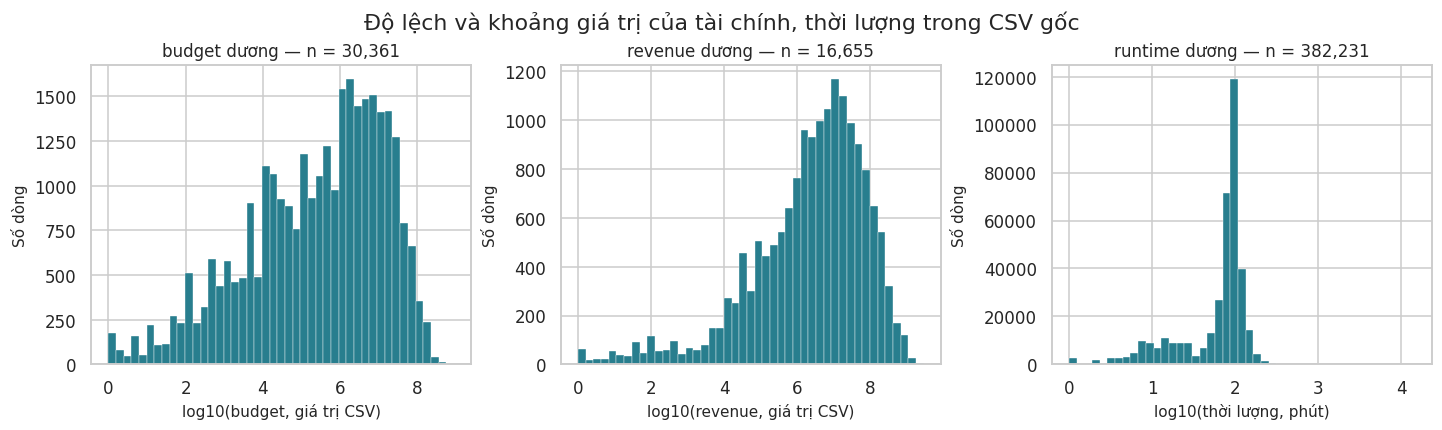

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), layout='constrained')
for ax, col in zip(axes, ['budget', 'revenue', 'runtime']):
    values = movies.loc[movies[col].gt(0), col]
    ax.hist(np.log10(values), bins=45, color='#287e8e', edgecolor='white', linewidth=.25)
    ax.set(title=f'{col} dương — n = {len(values):,}',
           xlabel=f'log10({col}, giá trị CSV)' if col != 'runtime' else 'log10(thời lượng, phút)',
           ylabel='Số dòng')
fig.suptitle('Độ lệch và khoảng giá trị của tài chính, thời lượng trong CSV gốc')
plt.show()

Hình tiếp theo cho thấy điểm và lượt chấm trên từng nền tảng. Phân phối điểm dùng toàn bộ CSV, có cả điểm TMDb bằng 0. Hình lượt chấm chỉ dùng giá trị dương. Những dòng có mã lặp vẫn xuất hiện trong các hình tổng quan này. Mục 6.1 sẽ so hai nền tảng trên cùng mẫu đã loại mã lặp.

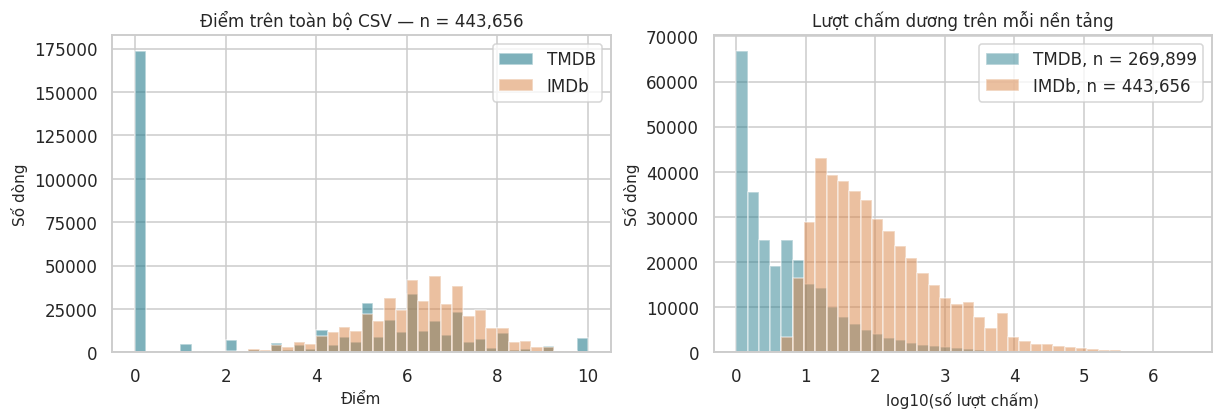

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7), layout='constrained')
axes[0].hist(movies.vote_average, bins=np.linspace(0, 10, 41), alpha=.6, label='TMDB', color='#287e8e')
axes[0].hist(movies.averageRating, bins=np.linspace(0, 10, 41), alpha=.5, label='IMDb', color='#d98243')
axes[0].set(title=f'Điểm trên toàn bộ CSV — n = {n:,}', xlabel='Điểm', ylabel='Số dòng')
axes[0].legend()
vote_bins = np.linspace(0, np.log10(movies[['vote_count', 'numVotes']].max().max()), 41)
for col, label, color in [('vote_count', 'TMDB', '#287e8e'), ('numVotes', 'IMDb', '#d98243')]:
    values = movies.loc[movies[col].gt(0), col]
    axes[1].hist(np.log10(values), bins=vote_bins, alpha=.5, color=color,
                 label=f'{label}, n = {len(values):,}')
axes[1].set(title='Lượt chấm dương trên mỗi nền tảng', xlabel='log10(số lượt chấm)', ylabel='Số dòng')
axes[1].legend()
plt.show()

### 3.4. Giá trị nào nằm xa phần lớn dữ liệu?

IQR dùng khoảng 25%–75% để đặt ngưỡng kiểm tra. Z-score đo khoảng cách tới trung bình theo số độ lệch chuẩn, với ngưỡng ở đây là `|z| > 3`. Với biến tài chính, thời lượng và lượt chấm, cả hai cách dùng cùng phần giá trị dương. Điểm dùng toàn bộ giá trị có sẵn.

Một giá trị vượt ngưỡng là trường hợp cần xem thêm. Các tác phẩm có ngân sách lớn hoặc thời lượng rất dài vẫn có thể là dữ liệu đúng.

In [16]:
outliers = []
for col in numeric_cols:
    s = movies.loc[movies[col].gt(0), col] if col in positive_cols else movies[col].dropna()
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    iqr_flagged = s.lt(lo) | s.gt(hi)
    z_scores = (s - s.mean()) / s.std(ddof=0)
    valid_z = z_scores.notna()
    z_flagged = z_scores.abs().gt(3)
    outliers.append([
        col, '> 0' if col in positive_cols else 'không thiếu', len(s), lo, hi,
        int(iqr_flagged.sum()), 100 * iqr_flagged.mean(), int(valid_z.sum()),
        int(z_flagged.sum()), 100 * z_flagged.loc[valid_z].mean(),
    ])

outlier_audit = pd.DataFrame(outliers, columns=[
    'cột', 'mẫu', 'n', 'ngưỡng dưới IQR', 'ngưỡng trên IQR',
    'số giá trị ngoài ngưỡng IQR', 'tỷ lệ ngoài ngưỡng IQR (%)', 'số giá trị tính được z-score', 'số giá trị có |z| > 3', 'tỷ lệ có |z| > 3 (%)',
])


display(outlier_audit[['cột', 'mẫu', 'n', 'số giá trị ngoài ngưỡng IQR',
                       'tỷ lệ ngoài ngưỡng IQR (%)', 'số giá trị có |z| > 3',
                       'tỷ lệ có |z| > 3 (%)']].round(2))

,cột,mẫu,n,số giá trị ngoài ngưỡng IQR,tỷ lệ ngoài ngưỡng IQR (%),số giá trị có |z| > 3,tỷ lệ có |z| > 3 (%)
0,budget,> 0,30361,4771,15.71,643,2.12
1,revenue,> 0,16655,2419,14.52,319,1.92
2,runtime,> 0,382231,5798,1.52,1196,0.31
3,vote_average,không thiếu,443656,0,0.00,0,0.00
4,vote_count,> 0,269899,40271,14.92,2135,0.79
5,averageRating,không thiếu,443656,5907,1.33,1932,0.44
6,numVotes,> 0,443656,71794,16.18,2739,0.62
7,popularity,> 0,425895,52031,12.22,1479,0.35


Trên phân phối lệch mạnh, giá trị rất lớn kéo trung bình và độ lệch chuẩn lên, nên z-score có thể phát hiện ít trường hợp hơn IQR. Ngưỡng số dưới đây cho phép kiểm tra trực tiếp mỗi cách tính.

In [17]:
display(outlier_audit[['cột', 'ngưỡng dưới IQR', 'ngưỡng trên IQR',
                       'số giá trị tính được z-score']].round(2))

,cột,ngưỡng dưới IQR,ngưỡng trên IQR,số giá trị tính được z-score
0,budget,-8962500.00,14977500.00,30361
1,revenue,-40667916.00,68695060.00,16655
2,runtime,-21.00,171.00,382231
3,vote_average,-9.30,15.50,443656
4,vote_count,-13.00,27.00,269899
5,averageRating,2.85,9.65,443656
6,numVotes,-474.00,854.00,443656
7,popularity,-1.05,3.34,425895


**Ngân sách**

Có ngân sách được ghi bằng 1 và một số giá trị rất lớn. Cần kiểm tra đơn vị và nguồn trước khi chọn ngưỡng lọc. Bảng lấy ba dòng lớn nhất và ba dòng dương nhỏ nhất, có thể có mã lặp.

In [18]:
positive = movies.loc[movies['budget'].gt(0)]
example_index = positive.nlargest(3, 'budget').index.union(positive.nsmallest(3, 'budget').index)
display(movies.loc[example_index, ['id', 'tconst', 'title', 'release_date', 'budget']]
        .sort_values('budget', ascending=False))

,id,tconst,title,release_date,budget
400850,1057999,tt27219440,Enea,2023-09-21,888000000
270441,1399448,tt6161168,Red Dead Redemption 2 (Movie),2024-03-21,540000000
270442,1399448,tt6161168,Red Dead Redemption 2 (Movie),2024-03-21,540000000
11073,571055,tt9061402,Down,2019-02-01,1
12213,16664,tt0297721,All About Lily Chou-Chou,2001-10-06,1
14900,20034,tt1093369,Hush,2008-08-13,1


**Doanh thu**

Doanh thu bằng 1 còn cần xác minh. Doanh thu rất cao có thể thuộc phim phát hành rộng rãi. Xếp hạng doanh thu trong CSV vẫn phụ thuộc cách nguồn ghi tiền tệ. Bảng lấy ba dòng lớn nhất và ba dòng dương nhỏ nhất, có thể có mã lặp.

In [19]:
positive = movies.loc[movies['revenue'].gt(0)]
example_index = positive.nlargest(3, 'revenue').index.union(positive.nsmallest(3, 'revenue').index)
display(movies.loc[example_index, ['id', 'tconst', 'title', 'release_date', 'revenue']]
        .sort_values('revenue', ascending=False))

,id,tconst,title,release_date,revenue
3,19995,tt0499549,Avatar,2009-12-15,2923706026
15,299534,tt4154796,Avengers: Endgame,2019-04-24,2800000000
281,76600,tt1630029,Avatar: The Way of Water,2022-12-14,2320250281
10094,14424,tt0497972,Sex and Death 101,2007-06-15,1
21385,500735,tt7823036,Finally Married,2018-01-25,1
21878,32834,tt0196106,MVP: Most Valuable Primate,2000-08-11,1


**Thời lượng**

Phim ngắn có thể chỉ dài một phút. Phim nghệ thuật hoặc chương trình dài cũng có thể kéo dài nhiều giờ. Loại tác phẩm ảnh hưởng lớn đến câu Q3. Bảng lấy ba dòng lớn nhất và ba dòng dương nhỏ nhất, có thể có mã lặp.

In [20]:
positive = movies.loc[movies['runtime'].gt(0)]
example_index = positive.nlargest(3, 'runtime').index.union(positive.nsmallest(3, 'runtime').index)
display(movies.loc[example_index, ['id', 'tconst', 'title', 'release_date', 'runtime']]
        .sort_values('runtime', ascending=False))

,id,tconst,title,release_date,runtime
197760,251800,tt2659636,Modern Times Forever,2011-03-23,14400
334721,710874,tt11707418,Svalbard minutt for minutt,2020-01-31,13319
102153,272074,tt0242365,Cinématon,1978-12-20,12480
7162,160,tt0000012,The Arrival of a Train at La Ciotat,1897-10-10,1
9018,774,tt0000010,Workers Leaving the Lumière Factory,1895-03-22,1
10846,82120,tt0000014,The Sprinkler Sprinkled,1895-06-10,1


**Đối chiếu một số trường hợp với nguồn**

| Trường hợp | Kết quả kiểm tra | Hướng dùng |
| --- | --- | --- |
| *Modern Times Forever*, `runtime = 14.400` phút | Tác giả SUPERFLEX công bố thời lượng 240 giờ, tương ứng đúng 14.400 phút. | Giữ khi khảo sát toàn bộ loại tác phẩm. Khi phân tích phim điện ảnh thông thường, cần định nghĩa phạm vi trước. |
| *Red Dead Redemption 2 (Movie)*, `tconst = tt6161168` | Mục IMDb tương ứng là *Red Dead Redemption II*, một trò chơi điện tử. Tên và ngày của dòng CSV cần được đối chiếu với mục TMDb. | Gắn nhãn cần kiểm tra liên kết giữa hai nguồn. |
| `budget = 1` hoặc `revenue = 1` | CSV thiếu thông tin để xác nhận đây là giá trị thực, giá trị thay thế hay lỗi nhập. | Đếm riêng và kiểm tra độ nhạy trong Q4 trước khi quyết định giữ hoặc loại. |

Nguồn kiểm tra ngày 19/11/2026 gồm [SUPERFLEX](https://superflex.net/works/modern_times_forever) và [IMDb của tt6161168](https://www.imdb.com/title/tt6161168/). Kiểm tra này chỉ xác nhận các trường hợp đã đối chiếu.

Mô tả [bản ghép Kaggle](https://www.kaggle.com/datasets/ggtejas/tmdb-imdb-merged-movies-dataset) dẫn nguồn tài chính nhưng chưa đủ để xác nhận mọi dòng v578 cùng một đơn vị và phạm vi doanh thu. Các bảng tài chính tiếp tục dùng nhãn **giá trị CSV**. Q4 cần ghi rõ cơ sở tiền tệ trước khi kết luận về chênh lệch doanh thu.

## 4. Cột phân loại, thể loại và ngày phát hành

Cột phân loại chia tác phẩm thành nhóm, chẳng hạn ngôn ngữ gốc hay trạng thái phát hành. Cột `genres` có thể chứa nhiều thể loại trên cùng một dòng.

### 4.1. Trạng thái phát hành và ngôn ngữ gốc

`Released` nghĩa là đã phát hành theo dữ liệu nguồn. Các trạng thái khác gồm đang hậu kỳ, đang sản xuất, lên kế hoạch, bị hủy và mới có tin đồn. Ngày ghi trong CSV và trạng thái đôi khi chưa nhất quán, nên hai cột cần đọc cùng nhau.

In [21]:
status_meanings = {'Released': 'Đã phát hành', 'Post Production': 'Đang hậu kỳ',
    'In Production': 'Đang sản xuất', 'Planned': 'Đang lên kế hoạch',
    'Canceled': 'Đã hủy', 'Rumored': 'Mới có tin đồn'}
status_counts = movies.status.value_counts()
display(pd.DataFrame({'Ý nghĩa': status_counts.index.map(status_meanings),
    'Số dòng': status_counts, 'Tỷ lệ (%)': 100 * status_counts / n}).round(2))

,Ý nghĩa,Số dòng,Tỷ lệ (%)
status,,,
Released,Đã phát hành,440762,99.35
Post Production,Đang hậu kỳ,1676,0.38
In Production,Đang sản xuất,1043,0.24
Planned,Đang lên kế hoạch,161,0.04
Canceled,Đã hủy,9,0.00
Rumored,Mới có tin đồn,5,0.00


Bảng ngôn ngữ liệt kê 15 nhóm nhiều dòng nhất. Mã `en` là tiếng Anh, `fr` là tiếng Pháp, `es` là tiếng Tây Ban Nha và `ja` là tiếng Nhật. Một nhóm nhiều dữ liệu có thể chi phối kết quả chung.

In [22]:
language_counts_raw = movies.original_language.value_counts()
display(pd.DataFrame({'Số dòng': language_counts_raw.head(15),
    'Tỷ lệ trong CSV (%)': 100 * language_counts_raw.head(15) / n}).round(2))
category_audit = []
for column in ['original_language', 'status', 'adult']:
    counts = movies.loc[~missing[column], column].value_counts()
    category_audit.append([column, len(counts), int(counts.le(5).sum()),
        int(counts.loc[counts.le(5)].sum()), int(missing[column].sum())])
display(pd.DataFrame(category_audit, columns=['Cột', 'Số nhãn khác nhau',
    'Số nhãn có tối đa 5 dòng', 'Số dòng thuộc nhãn ít gặp', 'Số dòng thiếu']))

,Số dòng,Tỷ lệ trong CSV (%)
original_language,,
en,242967,54.76
fr,24927,5.62
es,21908,4.94
de,21843,4.92
ja,13285,2.99
it,11978,2.70
ru,9472,2.13
pt,8287,1.87
zh,6907,1.56


,Cột,Số nhãn khác nhau,Số nhãn có tối đa 5 dòng,Số dòng thuộc nhãn ít gặp,Số dòng thiếu
0,original_language,158,38,79,0
1,status,6,1,5,0
2,adult,2,0,0,0


Các nhóm có tối đa 5 dòng được liệt kê để xem độ thưa dữ liệu. Khi so sánh Q3, ưu tiên các ngôn ngữ có đủ phim trong từng giai đoạn và báo số phim. Với Q2, cách gom nhãn hiếm phải được học trên tập huấn luyện.

Bảng kiểm tra cách viết tìm dấu cách thừa và nhãn khác nhau chỉ vì chữ hoa/chữ thường. Mã có đúng dạng hai chữ thường vẫn cần được đọc theo quy ước của TMDb.

In [23]:
display(language_counts_raw.loc[language_counts_raw.le(5)].head(20).to_frame('Ví dụ ngôn ngữ có tối đa 5 dòng'))
label_checks = []
for column in ['original_language', 'status']:
    values = movies.loc[~missing[column], column]
    pairs = pd.DataFrame({'gốc': values, 'chuẩn': values.str.strip().str.casefold()}).drop_duplicates()
    collisions = pairs.groupby('chuẩn')['gốc'].nunique()
    label_checks.append([column, int(values.ne(values.str.strip()).sum()), int(collisions.gt(1).sum())])
display(pd.DataFrame(label_checks, columns=['Cột', 'Dòng có dấu cách thừa', 'Nhãn có nhiều cách viết']))

,Ví dụ ngôn ngữ có tối đa 5 dòng
original_language,
fy,5
cr,4
ce,4
sm,4
tt,4
gn,4
lg,3
ny,3
ti,3


,Cột,Dòng có dấu cách thừa,Nhãn có nhiều cách viết
0,original_language,0,0
1,status,0,0


### 4.2. Một dòng có bao nhiêu thể loại khác nhau?

Đếm nhãn khác nhau sau khi tách danh sách. Ví dụ, `Animation, Animation` có **một** thể loại khác nhau và đồng thời được ghi nhận là có nhãn lặp. Việc này sửa lỗi đếm nhiều thể loại ở bản trước.

In [24]:
raw_genre_lists = movies.genres.fillna('').str.split(',').map(
    lambda parts: [part.strip() for part in parts if part.strip()])
genre_duplicate_tokens = raw_genre_lists.map(lambda parts: len(parts) != len(set(parts)))
genre_lists = raw_genre_lists.map(lambda parts: sorted(set(parts)))
genre_count = genre_lists.map(len)
genre_brackets = movies.genres.fillna('').str.contains(r'[\[\]{}]', regex=True)
genre_audit = pd.Series({
    'Dòng thiếu thể loại': int(missing.genres.sum()),
    'Dòng có ít nhất hai thể loại khác nhau': int(genre_count.gt(1).sum()),
    'Dòng lặp nhãn thể loại': int(genre_duplicate_tokens.sum()),
    'Dòng có dấu ngoặc cần xem cách tách': int(genre_brackets.sum()),
    'Số thể loại khác nhau nhiều nhất trong một dòng': int(genre_count.max()),
})
display(genre_audit.to_frame('Kết quả'))
display(movies.loc[genre_duplicate_tokens, ['title', 'genres']].head(3))

,Kết quả
Dòng thiếu thể loại,83813
Dòng có ít nhất hai thể loại khác nhau,171180
Dòng lặp nhãn thể loại,95
Dòng có dấu ngoặc cần xem cách tách,0
Số thể loại khác nhau nhiều nhất trong một dòng,11


,title,genres
68737,Ded Moroz and the Grey Wolf,"Animation, Animation"
72418,Hayat Sevince Güzel,"Comedy, Family, Drama, Romance, Family, Comedy..."
73013,Deadly Hero,"Drama, Thriller, Crime, Drama"


Bảng tiếp theo đếm mỗi thể loại tối đa một lần trên một dòng. Một tác phẩm thuộc hai thể loại sẽ góp mặt trong hai hàng, nên tổng tỷ lệ thể loại có thể vượt 100%. Khi phân tích tài chính, cần giữ mã tác phẩm để kiểm soát việc đếm lặp.

In [25]:
genre_tokens = genre_lists.explode().dropna()
genre_counts = genre_tokens.value_counts()
display(pd.DataFrame({'Số dòng có thể loại': genre_counts,
    'Tỷ lệ trong CSV (%)': 100 * genre_counts / n}).round(2))
display(genre_count.value_counts().sort_index().rename_axis('Số thể loại khác nhau')
        .to_frame('Số dòng'))

,Số dòng có thể loại,Tỷ lệ trong CSV (%)
genres,,
Drama,140009,31.56
Comedy,92583,20.87
Documentary,59518,13.42
Romance,35904,8.09
Thriller,33768,7.61
Action,32986,7.44
Horror,31615,7.13
Animation,26322,5.93
Crime,25105,5.66


,Số dòng
Số thể loại khác nhau,
0,83813
1,188663
2,108484
3,47949
4,11434
5,2569
6,626
7,94
8,18


### 4.3. Ngày phát hành có đọc được và hợp lý không?

Bảng kiểm tra ngày viết sai dạng, ngày đọc không được, và ngày sau **05/11/2026**, là ngày nhóm tải CSV. Một lịch phát hành tương lai có thể hợp lệ với tác phẩm đang sản xuất. Nhãn `Released` kèm ngày tương lai cần được đối chiếu riêng.

In [26]:
release_dates = pd.to_datetime(movies.release_date, format='%Y-%m-%d', errors='coerce')
release_years = release_dates.dt.year
invalid_dates = ~missing.release_date & release_dates.isna()
non_iso = ~missing.release_date & ~movies.release_date.str.fullmatch(r'\d{4}-\d{2}-\d{2}', na=False)
date_audit = pd.Series({'thiếu release_date': int(missing.release_date.sum()),
    'có ghi ngày nhưng không đọc được': int(invalid_dates.sum()),
    'ngày viết sai dạng năm-tháng-ngày': int(non_iso.sum()),
    'ngày sớm nhất': str(release_dates.min().date()),
    'ngày muộn nhất': str(release_dates.max().date()),
    'sau ngày nhóm tải 05/11/2026': int(release_dates.gt(DOWNLOAD_DATE).sum()),
    'Released nhưng ngày sau ngày tải': int((release_dates.gt(DOWNLOAD_DATE) & movies.status.eq('Released')).sum())})
display(date_audit.to_frame('Kết quả'))
display(movies.loc[invalid_dates | non_iso | release_dates.gt(DOWNLOAD_DATE),
                   ['id', 'tconst', 'title', 'release_date', 'status']].head(15))

,Kết quả
thiếu release_date,25363
có ghi ngày nhưng không đọc được,0
ngày viết sai dạng năm-tháng-ngày,0
ngày sớm nhất,1874-12-09
ngày muộn nhất,2029-10-13
sau ngày nhóm tải 05/11/2026,3
Released nhưng ngày sau ngày tải,2


,id,tconst,title,release_date,status
272007,1225835,tt8270746,শূন্যতা,2027-04-21,Released
286448,1355413,tt5835938,Pela Adhi Akshar,2027-03-24,In Production
287509,1227249,tt10333734,Indiana Jones: Return of Elsa Schneider,2029-10-13,Released


Các ngày có giá trị đều đọc được, nhưng có 3 dòng mang ngày sau ngày tải, trong đó 2 dòng ghi `Released`. Khoảng ngày 1874–2029 là khoảng ngày phát hành ghi trong CSV. Thời điểm lấy điểm và lượt chấm từ mỗi nguồn chưa được xác nhận.

Bảng dưới cho biết số dòng theo thời gian trước và sau khi chọn hai mã chỉ xuất hiện một lần. Mục 6 sẽ áp dụng thêm trạng thái và điều kiện riêng từng câu.

In [27]:
period_labels = ['1990–1999', '2000–2009', '2010–2019', '2020–2024']
raw_periods = pd.cut(release_years, bins=[1989, 1999, 2009, 2019, 2024], labels=period_labels)
coverage_1990_2024 = pd.DataFrame({
    'số dòng trong CSV gốc': raw_periods.value_counts(sort=False),
    'số dòng có cả hai mã chỉ xuất hiện một lần': raw_periods.loc[unique_keys].value_counts(sort=False),
})
display(coverage_1990_2024)
display(pd.Series({
    'thiếu hoặc không đọc được ngày': int(release_dates.isna().sum()),
    'trước 1990': int(release_years.lt(1990).sum()),
    '1990–2024': int(release_years.between(1990, 2024).sum()),
    'sau 2024': int(release_years.gt(2024).sum()),
}, name='Số dòng theo năm phát hành trong CSV gốc'))

,số dòng trong CSV gốc,số dòng có cả hai mã chỉ xuất hiện một lần
release_date,,
1990–1999,39120,38788
2000–2009,69832,68860
2010–2019,123528,121025
2020–2024,50388,45267


thiếu hoặc không đọc được ngày     25363
trước 1990                        135411
1990–2024                         282868
sau 2024                              14
Name: Số dòng theo năm phát hành trong CSV gốc, dtype: int64

## 5. Dữ liệu thiếu và cách xử lý dự kiến

### 5.1. Cột nào thiếu nhiều?

Ô trống, ký hiệu IMDb `\N` và ô chỉ có dấu cách đều được tính là thiếu. Ngân sách, doanh thu và thời lượng bằng 0 được đếm riêng ở mục 3. Tỷ lệ ở đây dùng **443.656 dòng** của toàn bộ CSV làm mẫu số.

In [28]:
missing_table = pd.DataFrame({
    'số giá trị được đọc là thiếu': movies.isna().sum(),
    'số ô chỉ có dấu cách': space_only,
    'số thiếu': missing.sum(),
    'tỷ lệ thiếu (%)': 100 * missing.mean(),
}).sort_values('số thiếu', ascending=False)
display(missing_table[['số thiếu', 'tỷ lệ thiếu (%)']].round(2))

,số thiếu,tỷ lệ thiếu (%)
homepage,387892,87.43
tagline,349641,78.81
keywords,272009,61.31
backdrop_path,256638,57.85
production_companies,180269,40.63
production_countries,121880,27.47
spoken_languages,109772,24.74
genres,83813,18.89
poster_path,79371,17.89
cast,69646,15.70


Có ô chứa chữ nhưng thực chất chỉ là dấu cách. Bảng nhỏ này cho biết những cột phát sinh thêm giá trị thiếu khi kiểm tra dấu cách, để người đọc hiểu vì sao số thiếu có thể cao hơn kết quả đọc CSV ban đầu.

In [29]:
display(missing_table.loc[space_only.gt(0),
        ['số giá trị được đọc là thiếu', 'số ô chỉ có dấu cách', 'số thiếu']])

,số giá trị được đọc là thiếu,số ô chỉ có dấu cách,số thiếu
homepage,387889,3,387892
overview,44974,64,45038


Trong các cột dùng cho bốn câu hỏi, ngày phát hành và thể loại có ô thiếu. Các cột số có 0% ô thiếu vẫn cần kiểm tra số 0 và các giá trị đáng nghi đã nêu ở mục 3.

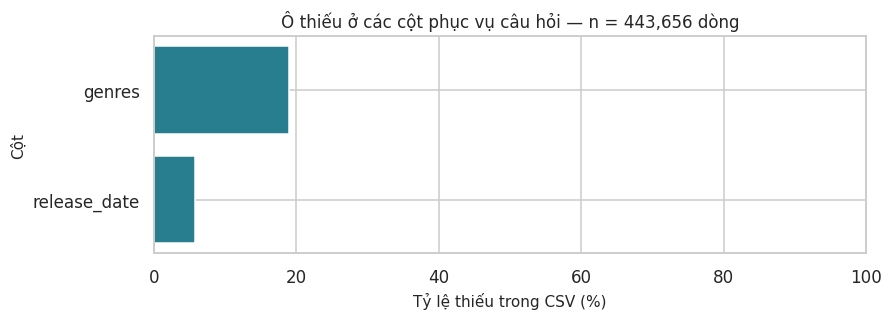

In [30]:
important = ['release_date', 'genres', 'original_language', 'runtime', 'budget', 'revenue',
             'vote_average', 'vote_count', 'averageRating', 'numVotes']
shown = missing_table.loc[important].query('`số thiếu` > 0').sort_values('tỷ lệ thiếu (%)')
fig, ax = plt.subplots(figsize=(8, 2.8), layout='constrained')
ax.barh(shown.index, shown['tỷ lệ thiếu (%)'], color='#287e8e')
ax.set(xlabel='Tỷ lệ thiếu trong CSV (%)', ylabel='Cột', xlim=(0, 100),
       title=f'Ô thiếu ở các cột phục vụ câu hỏi — n = {n:,} dòng')
plt.show()

### 5.2. Các cột có thường thiếu cùng nhau không?

Mỗi hàng dưới là một tổ hợp có hoặc thiếu dữ liệu. `Có` trong cột `Thiếu ngày` nghĩa là dòng đó thiếu ngày phát hành. Bảng giúp xem việc lọc một cột có đồng thời loại nhiều dòng thiếu cột khác hay không.

In [31]:
pattern_columns = ['release_date', 'genres', 'original_language']
patterns = missing[pattern_columns].value_counts().rename('Số dòng').reset_index()
patterns['Tỷ lệ trong CSV (%)'] = 100 * patterns['Số dòng'] / n
pattern_view = patterns.rename(columns={'release_date': 'Thiếu ngày',
    'genres': 'Thiếu thể loại', 'original_language': 'Thiếu ngôn ngữ'})
for column in ['Thiếu ngày', 'Thiếu thể loại', 'Thiếu ngôn ngữ']:
    pattern_view[column] = pattern_view[column].map({True: 'Có', False: 'Không'})
display(pattern_view.round(2))
joint_missing = int((missing.release_date & missing.genres).sum())
display(Markdown(f'Có **{joint_missing:,} dòng** thiếu cả ngày và thể loại, chiếm '
    f'**{joint_missing / missing.release_date.sum():.2%}** các dòng thiếu ngày phát hành.'))

,Thiếu ngày,Thiếu thể loại,Thiếu ngôn ngữ,Số dòng,Tỷ lệ trong CSV (%)
0,Không,Không,Không,354549,79.92
1,Không,Có,Không,63744,14.37
2,Có,Có,Không,20069,4.52
3,Có,Không,Không,5294,1.19


Có **20,069 dòng** thiếu cả ngày và thể loại, chiếm **79.13%** các dòng thiếu ngày phát hành.

### 5.3. Việc thiếu dữ liệu khác nhau giữa các nhóm ra sao?

Trong các bảng tiếp theo, mỗi phần trăm dùng **số dòng của chính hàng đó** làm mẫu số. Chẳng hạn, tỷ lệ thiếu ngày của nhóm `Planned` được tính trong các dòng `Planned`. Các cột bằng 0 vẫn được ghi riêng để theo dõi tình trạng dữ liệu.

In [32]:
availability = missing[pattern_columns].rename(columns=lambda col: 'thiếu_' + col).copy()
availability['budget_bằng_0'] = movies.budget.eq(0)
availability['revenue_bằng_0'] = movies.revenue.eq(0)
availability['runtime_bằng_0'] = movies.runtime.eq(0)
availability['TMDB_không_lượt_chấm'] = movies.vote_count.eq(0)

def missing_by_group(groups):
    result = availability.groupby(groups, observed=True, dropna=False).mean().mul(100)
    result.insert(0, 'Số dòng', groups.value_counts(dropna=False))
    return result.rename(columns={
        'thiếu_release_date': 'Thiếu ngày (%)', 'thiếu_genres': 'Thiếu thể loại (%)',
        'thiếu_original_language': 'Thiếu ngôn ngữ (%)', 'budget_bằng_0': 'Ngân sách 0 (%)',
        'revenue_bằng_0': 'Doanh thu 0 (%)', 'runtime_bằng_0': 'Thời lượng 0 (%)',
        'TMDB_không_lượt_chấm': 'TMDb chưa có lượt (%)'}).round(2)

display(missing_by_group(movies.status).drop(columns='Thiếu ngôn ngữ (%)'))

,Số dòng,Thiếu ngày (%),Thiếu thể loại (%),Ngân sách 0 (%),Doanh thu 0 (%),Thời lượng 0 (%),TMDb chưa có lượt (%)
status,,,,,,,
Canceled,9,88.89,33.33,88.89,100.00,66.67,100.00
In Production,1043,37.20,16.30,92.71,99.90,68.46,100.00
Planned,161,70.19,14.91,91.93,100.00,84.47,100.00
Post Production,1676,57.10,12.77,92.30,100.00,64.32,99.88
Released,440762,5.42,18.92,93.16,96.22,13.50,38.77
Rumored,5,100.00,20.00,100.00,100.00,80.00,80.00


Ngày phát hành thiếu ở **5,42%** nhóm `Released` và **70,19%** nhóm `Planned`. Trạng thái vì vậy liên quan đến khả năng có ngày trong CSV. Những con số này mô tả mẫu hình, còn nguyên nhân thiếu của từng dòng cần nguồn đối chiếu.

Bảng ngôn ngữ dưới giữ 10 nhóm đông nhất và gom các nhóm còn lại cho lần xem tổng quan này.

In [33]:
top_languages = movies.original_language.value_counts().head(10).index
language_groups = movies.original_language.where(
    movies.original_language.isin(top_languages), 'Các ngôn ngữ còn lại')
display(missing_by_group(language_groups).drop(columns='Thiếu ngôn ngữ (%)'))

,Số dòng,Thiếu ngày (%),Thiếu thể loại (%),Ngân sách 0 (%),Doanh thu 0 (%),Thời lượng 0 (%),TMDb chưa có lượt (%)
original_language,,,,,,,
Các ngôn ngữ còn lại,76007,2.70,11.90,95.69,97.39,17.86,40.20
de,21843,2.92,11.93,97.83,98.82,36.86,42.74
en,242967,8.07,23.41,90.76,95.42,9.10,41.87
es,21908,4.10,19.34,95.79,97.04,21.28,27.30
fr,24927,2.88,16.62,95.92,97.50,15.11,29.79
hi,6075,1.89,18.40,92.16,93.28,18.85,36.89
it,11978,3.34,13.81,96.72,97.65,22.82,27.84
ja,13285,0.78,10.52,98.07,96.50,3.20,25.98
pt,8287,3.21,13.50,96.11,98.66,21.30,42.51


Bảng theo thập niên giúp xem các tác phẩm ở giai đoạn khác nhau có mức đầy đủ tài chính và thời lượng khác nhau không. Dòng thiếu ngày được giữ thành một nhóm riêng.

In [34]:
decades = ((release_years // 10) * 10).astype('Int64').astype('string').fillna('Thiếu hoặc không đọc được ngày')
display(missing_by_group(decades).drop(columns='Thiếu ngôn ngữ (%)'))

,Số dòng,Thiếu ngày (%),Thiếu thể loại (%),Ngân sách 0 (%),Doanh thu 0 (%),Thời lượng 0 (%),TMDb chưa có lượt (%)
release_date,,,,,,,
1870,19,0.0,15.79,94.74,100.00,15.79,57.89
1880,33,0.0,21.21,93.94,100.00,21.21,69.70
1890,1058,0.0,33.74,100.00,100.00,2.65,8.13
1900,2035,0.0,38.67,99.66,100.00,2.21,20.84
1910,4024,0.0,21.32,99.20,99.55,10.16,36.98
1920,5638,0.0,14.19,98.19,98.81,15.68,47.87
1930,12763,0.0,9.23,97.79,99.00,9.44,38.54
1940,11897,0.0,7.81,97.81,98.44,7.14,33.81
1950,15495,0.0,10.93,97.71,98.30,12.80,33.31


Bảng theo thể loại cho biết khả năng có thông tin phục vụ Q3 và Q4. Một dòng có nhiều thể loại góp mặt trong nhiều hàng. Mỗi tỷ lệ vẫn dùng số dòng của thể loại đó làm mẫu số.

In [35]:
genre_quality = availability[['thiếu_release_date', 'budget_bằng_0', 'revenue_bằng_0', 'runtime_bằng_0']].copy()
genre_quality['genre'] = genre_lists
genre_quality = genre_quality.explode('genre').dropna(subset=['genre'])
genre_availability = genre_quality.groupby('genre').mean().mul(100)
genre_availability.insert(0, 'Số dòng', genre_quality.groupby('genre').size())
display(genre_availability.rename(columns={'thiếu_release_date': 'Thiếu ngày (%)',
    'budget_bằng_0': 'Ngân sách 0 (%)', 'revenue_bằng_0': 'Doanh thu 0 (%)',
    'runtime_bằng_0': 'Thời lượng 0 (%)'}).sort_values('Số dòng', ascending=False).head(10).round(2))

,Số dòng,Thiếu ngày (%),Ngân sách 0 (%),Doanh thu 0 (%),Thời lượng 0 (%)
genre,,,,,
Drama,140009,1.08,91.82,94.53,9.78
Comedy,92583,1.49,91.36,93.85,12.06
Documentary,59518,1.68,96.35,98.96,8.25
Romance,35904,0.98,90.60,91.75,8.71
Thriller,33768,1.99,83.46,89.98,7.30
Action,32986,2.34,85.57,89.75,10.17
Horror,31615,2.92,83.14,94.10,6.39
Animation,26322,1.31,95.62,95.75,5.07
Crime,25105,1.23,88.56,91.58,9.21


### 5.4. Xử lý từng nhóm cột như thế nào?

Nguyên nhân từng ô bị thiếu chưa được xác minh. Phương án dưới dựa vào vai trò của cột trong từng câu hỏi. Mọi bước lọc ở mục 6 đều báo số dòng còn lại.

| Cột | Hướng xử lý cho bước phân tích |
| --- | --- |
| `release_date` | Dòng thiếu hoặc ngày không đọc được nằm ngoài các mẫu cần năm phát hành. Giữ bản gốc để thống kê mức thiếu. |
| `genres` | Q1 giữ dòng thiếu thể loại khi so điểm chung, rồi chỉ dùng phần có thể loại cho bảng theo thể loại. Q2 giữ giá trị thiếu để tạo nhóm chưa có thông tin trong Pipeline. Q3 và Q4 cần thể loại nên lọc phần có nhãn. |
| `runtime` | Thời lượng 0 được xem là chưa đủ thông tin trong bản phân tích. Q2 có thể tạo cột đánh dấu ô thiếu và điền bằng trung vị học từ train. Q3 dùng phần thời lượng dương, rồi kiểm tra thêm phạm vi độ dài. Các cực trị được xem từng trường hợp. |
| `budget`, `revenue` | Q4 dùng cả hai dương, kiểm tra riêng giá trị rất nhỏ và cực trị, xác minh tiền tệ trước khi so doanh thu. Giữ số 0 trong báo cáo chất lượng. |
| `vote_average`, `vote_count`, `averageRating`, `numVotes` | Q1 giữ điểm đúng thang và lượt chấm đủ ngưỡng ở cả hai bên. Q2 cần điểm IMDb làm mục tiêu. Các điểm IMDb thiếu hoặc ngoài thang sẽ bị loại khỏi mẫu ML. |
| `original_language` | CSV hiện có dữ liệu ở mọi dòng. Q2 tạo nhóm cho nhãn thiếu hoặc mới và học cách gom nhãn hiếm trên train. Q3 báo số mẫu của từng ngôn ngữ. |
| `production_companies`, `production_countries`, `spoken_languages`, `directors`, `writers`, `cast` | Ngoài đầu vào hiện tại của Q1–Q4. Giữ dữ liệu thiếu và mô tả tỷ lệ trong bảng tổng quan. Khi chọn thêm cột, cần kiểm tra danh sách nhiều tên và số mẫu theo nhóm. |
| `overview`, `tagline`, `keywords`, `homepage`, `poster_path`, `backdrop_path` | Ngoài phạm vi phân tích hiện tại. Thiếu các cột này vẫn giữ được dòng có dữ liệu phù hợp cho Q1–Q4. |

Cách điền thiếu và mã hóa của Q2 được học từ tập huấn luyện trong Pipeline. Thời lượng và ngày phát hành hiện là giá trị trong bản CSV tải về, nên chưa có bằng chứng chúng đã giống hệt giá trị được biết ở một mốc lịch sử cụ thể.

## 6. Mẫu dữ liệu và các mối liên hệ phục vụ Q1–Q4

Các mẫu bắt đầu từ **425.189 dòng có cả hai mã chỉ xuất hiện một lần**. Mỗi câu dùng những cột và điều kiện riêng. Các bảng ở phần này giúp chọn phương pháp cho notebook phân tích.

### 6.1. Cần lọc những gì cho mỗi câu?

Q1 so hai điểm của cùng tác phẩm, dùng ngưỡng 10 và 100 lượt ở mỗi bên. Q2 dùng điểm IMDb làm mục tiêu và giữ đầu vào thiếu để chuẩn bị Pipeline. Q3 cần thời lượng dương và thể loại. Q4 cần ngân sách, doanh thu dương và thể loại.

Các mẫu đều dùng `Released`. Điều kiện này được bổ sung cho Q1 và Q2 để bám sát tác phẩm đã phát hành. Q1, Q3 và Q4 giữ năm 1990–2024. Q2 giữ các năm đến hết 2024 để chia phần trước 2020 và phần 2020–2024.

In [36]:
analysis_base = movies.loc[unique_keys, focus_columns + ['title']].copy()
analysis_base['release_year'] = release_years.loc[analysis_base.index]
analysis_base['period'] = raw_periods.loc[analysis_base.index]
analysis_base['genre_list'] = genre_lists.loc[analysis_base.index]
has_genre = genre_count.gt(0)
year_1990_2024 = release_years.between(1990, 2024)
released = movies.status.eq('Released')
valid_imdb = movies.averageRating.between(1, 10) & movies.numVotes.gt(0)
valid_pair = movies.vote_average.between(0, 10) & valid_imdb & movies.vote_count.gt(0)
question_steps = {
    'Q1': [('Trạng thái Released', released), ('Năm 1990–2024', year_1990_2024),
           ('Có hai điểm hợp lệ và lượt chấm', valid_pair),
           ('Ít nhất 10 lượt ở mỗi nền tảng', movies.vote_count.ge(10) & movies.numVotes.ge(10))],
    'Q2': [('Trạng thái Released', released),
           ('Có năm phát hành và năm ≤ 2024', release_years.notna() & release_years.le(2024)),
           ('Có điểm IMDb từ 1 đến 10 và có lượt', valid_imdb)],
    'Q3': [('Trạng thái Released', released), ('Năm 1990–2024', year_1990_2024),
           ('Thời lượng dương', movies.runtime.gt(0)), ('Có thể loại', has_genre)],
    'Q4': [('Trạng thái Released', released), ('Năm 1990–2024', year_1990_2024),
           ('Ngân sách dương', movies.budget.gt(0)), ('Doanh thu dương', movies.revenue.gt(0)),
           ('Có thể loại', has_genre)],
}

In [37]:
flow_rows = []
question_masks = {}
for question, steps in question_steps.items():
    selected = unique_keys.copy()
    flow_rows.append([question, 'Bắt đầu từ hai mã chỉ xuất hiện một lần', int(selected.sum()), 0])
    for label, condition in steps:
        before = int(selected.sum())
        selected &= condition
        after = int(selected.sum())
        flow_rows.append([question, label, after, before - after])
    question_masks[question] = selected
sample_flow = pd.DataFrame(flow_rows, columns=['câu', 'điều kiện thêm vào', 'số dòng còn lại', 'loại ở bước này'])
question_frames = {question: analysis_base.loc[mask.loc[analysis_base.index]].copy()
                   for question, mask in question_masks.items()}
question_sizes = pd.Series({question: len(frame) for question, frame in question_frames.items()}, name='Số tác phẩm')
for question in question_steps:
    display(Markdown(f'**{question} — số dòng sau từng điều kiện**'))
    display(sample_flow.loc[sample_flow['câu'].eq(question)].drop(columns='câu').reset_index(drop=True))

**Q1 — số dòng sau từng điều kiện**

,điều kiện thêm vào,số dòng còn lại,loại ở bước này
0,Bắt đầu từ hai mã chỉ xuất hiện một lần,425189,0
1,Trạng thái Released,422385,2804
2,Năm 1990–2024,272584,149801
3,Có hai điểm hợp lệ và lượt chấm,179208,93376
4,Ít nhất 10 lượt ở mỗi nền tảng,55418,123790


**Q2 — số dòng sau từng điều kiện**

,điều kiện thêm vào,số dòng còn lại,loại ở bước này
0,Bắt đầu từ hai mã chỉ xuất hiện một lần,425189,0
1,Trạng thái Released,422385,2804
2,Có năm phát hành và năm ≤ 2024,407278,15107
3,Có điểm IMDb từ 1 đến 10 và có lượt,407278,0


**Q3 — số dòng sau từng điều kiện**

,điều kiện thêm vào,số dòng còn lại,loại ở bước này
0,Bắt đầu từ hai mã chỉ xuất hiện một lần,425189,0
1,Trạng thái Released,422385,2804
2,Năm 1990–2024,272584,149801
3,Thời lượng dương,242634,29950
4,Có thể loại,209322,33312


**Q4 — số dòng sau từng điều kiện**

,điều kiện thêm vào,số dòng còn lại,loại ở bước này
0,Bắt đầu từ hai mã chỉ xuất hiện một lần,425189,0
1,Trạng thái Released,422385,2804
2,Năm 1990–2024,272584,149801
3,Ngân sách dương,23684,248900
4,Doanh thu dương,8107,15577
5,Có thể loại,8049,58


Các mẫu có thành phần khác nhau. Bảng dưới xem ngôn ngữ gốc tiếng Anh, thể loại thiếu và thời lượng 0 trong mỗi mẫu. Chẳng hạn, kết quả tài chính phải được diễn giải trong nhóm có đủ số liệu tài chính, vì nhóm đó có thể tập trung nhiều hơn vào một số ngôn ngữ và loại phim.

In [38]:
profiles = pd.DataFrame({label: {
    'Số dòng': len(frame),
    'Ngôn ngữ gốc en (%)': 100 * frame.original_language.eq('en').mean(),
    'Thiếu thể loại (%)': 100 * missing.loc[frame.index, 'genres'].mean(),
    'Thời lượng 0 (%)': 100 * frame.runtime.eq(0).mean(),
} for label, frame in [('CSV gốc', movies), ('Hai mã không lặp', analysis_base), *question_frames.items()]}).T
display(profiles.round(2))

,Số dòng,Ngôn ngữ gốc en (%),Thiếu thể loại (%),Thời lượng 0 (%)
CSV gốc,443656.0,54.76,18.89,13.85
Hai mã không lặp,425189.0,53.58,17.46,12.97
Q1,55418.0,56.49,0.67,1.55
Q2,407278.0,52.68,15.16,11.48
Q3,209322.0,55.07,0.00,0.00
Q4,8049.0,72.68,0.00,0.87


### 6.2. Q1 — So điểm IMDb và TMDb trên cùng tác phẩm

Tính **chênh lệch = điểm TMDb − điểm IMDb**. Số dương nghĩa là điểm TMDb cao hơn. Khoảng cách tuyệt đối bỏ dấu để đo hai điểm cách nhau bao xa. Bảng dùng các mẫu lồng nhau khi thay ngưỡng lượt chấm.

In [39]:
paired_ratings = analysis_base.loc[(released & year_1990_2024 & valid_pair).loc[analysis_base.index]].copy()
paired_ratings['rating_gap'] = paired_ratings.vote_average - paired_ratings.averageRating
rating_rows = []
for threshold in [1, 10, 100]:
    subset = paired_ratings.loc[paired_ratings.vote_count.ge(threshold) & paired_ratings.numVotes.ge(threshold)]
    rating_rows.append({'lượt tối thiểu ở cả hai': threshold, 'n': len(subset),
        'có thể loại': int(subset.genre_list.map(len).gt(0).sum()),
        'Δ trung bình': subset.rating_gap.mean(), 'Δ trung vị': subset.rating_gap.median(),
        '|Δ| trung bình': subset.rating_gap.abs().mean(),
        'Spearman': subset.vote_average.corr(subset.averageRating, method='spearman')})
rating_sensitivity = pd.DataFrame(rating_rows).set_index('lượt tối thiểu ở cả hai')
display(rating_sensitivity.rename(columns={'n': 'Số tác phẩm', 'có thể loại': 'Có thể loại',
    'Δ trung bình': 'Lệch trung bình', 'Δ trung vị': 'Lệch trung vị',
    '|Δ| trung bình': 'Khoảng cách trung bình'}).round(3))
q1 = question_frames['Q1'].copy()
q1['rating_gap'] = q1.vote_average - q1.averageRating

,Số tác phẩm,Có thể loại,Lệch trung bình,Lệch trung vị,Khoảng cách trung bình,Spearman
lượt tối thiểu ở cả hai,,,,,,
1,179208,161782,-0.226,-0.144,1.186,0.499
10,55418,55044,0.094,0.000,0.561,0.769
100,14559,14558,0.172,0.030,0.398,0.844


In [40]:
display(Markdown(
    f'Ngưỡng 10 giữ **{int(rating_sensitivity.loc[10, "n"]):,} tác phẩm**, '
    f'còn ngưỡng 100 giữ **{int(rating_sensitivity.loc[100, "n"]):,}**. '
    f'Khoảng cách tuyệt đối trung bình lần lượt là **{rating_sensitivity.loc[10, "|Δ| trung bình"]:.3f}** '
    f'và **{rating_sensitivity.loc[100, "|Δ| trung bình"]:.3f} điểm**. '
    'Việc nâng ngưỡng thay đổi thành phần tác phẩm được giữ lại. Kết quả này chưa giải thích nguyên nhân hai nền tảng lệch điểm.'))

Ngưỡng 10 giữ **55,418 tác phẩm**, còn ngưỡng 100 giữ **14,559**. Khoảng cách tuyệt đối trung bình lần lượt là **0.561** và **0.398 điểm**. Việc nâng ngưỡng thay đổi thành phần tác phẩm được giữ lại. Kết quả này chưa giải thích nguyên nhân hai nền tảng lệch điểm.

**Số lượt chấm ở hai nền tảng khác nhau ra sao?**

Để so công bằng về nhóm tác phẩm, bảng đếm trên cùng các tác phẩm có điểm và ít nhất một lượt ở cả hai bên trong giai đoạn 1990–2024. Hai cột đếm riêng số tác phẩm đạt từng ngưỡng ở IMDb và TMDb. Tổng lượt trên nhiều phim có thể bao gồm một người dùng nhiều lần, nên CSV chỉ cho biết lượt chấm.

In [41]:
platform_rows = []
for threshold in [1, 10, 100, 1000, 10000]:
    platform_rows.append([threshold, int(paired_ratings.numVotes.ge(threshold).sum()),
        int(paired_ratings.vote_count.ge(threshold).sum())])
display(pd.DataFrame(platform_rows, columns=['Ngưỡng lượt chấm', 'Số tác phẩm đạt ngưỡng IMDb',
    'Số tác phẩm đạt ngưỡng TMDb']))
display(paired_ratings[['numVotes', 'vote_count']].median()
    .rename(index={'numVotes': 'IMDb', 'vote_count': 'TMDb'}).to_frame('Trung vị lượt chấm trên mỗi tác phẩm'))

,Ngưỡng lượt chấm,Số tác phẩm đạt ngưỡng IMDb,Số tác phẩm đạt ngưỡng TMDb
0,1,179208,179208
1,10,175700,55437
2,100,111681,14568
3,1000,38110,3488
4,10000,9786,251


,Trung vị lượt chấm trên mỗi tác phẩm
IMDb,181.0
TMDb,4.0


Hình dùng mẫu chính có ít nhất 10 lượt ở mỗi bên. Mỗi ô lục giác gộp các tác phẩm có hai điểm gần nhau, màu sáng nghĩa là nhiều tác phẩm. Đường chéo thể hiện hai điểm bằng nhau. Tương quan cao vẫn có thể đi cùng chênh lệch điểm, nên cần đọc cả bảng chênh lệch ở trên.

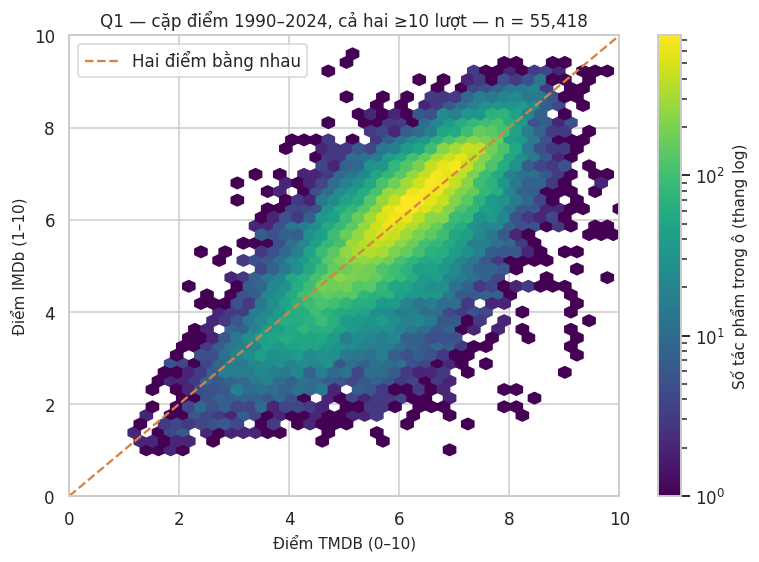

In [42]:
fig, ax = plt.subplots(figsize=(6.8, 5), layout='constrained')
hb = ax.hexbin(q1.vote_average, q1.averageRating, gridsize=40, mincnt=1, bins='log', cmap='viridis')
ax.plot([0, 10], [0, 10], '--', color='#d98243', label='Hai điểm bằng nhau')
ax.set(title=f'Q1 — cặp điểm 1990–2024, cả hai ≥10 lượt — n = {len(q1):,}',
       xlabel='Điểm TMDB (0–10)', ylabel='Điểm IMDb (1–10)', xlim=(0, 10), ylim=(0, 10))
ax.legend(loc='upper left')
fig.colorbar(hb, ax=ax, label='Số tác phẩm trong ô (thang log)')
plt.show()

**Theo thể loại, có còn cùng một mẫu hình không?**

Bảng chọn 8 thể loại có nhiều mẫu nhất ở ngưỡng 10. Hai ngưỡng cùng dùng phần có nhãn thể loại. Mỗi tác phẩm được đếm một lần trong từng thể loại của nó. `TB` trong tên cột nghĩa là trung bình. Chênh lệch ở đây là mô tả sơ bộ, còn khoảng tin cậy và so sánh có kiểm soát sẽ được thực hiện trong notebook 02.

In [43]:
q1_genre_source = q1[['id', 'genre_list', 'rating_gap']].explode('genre_list').dropna(subset=['genre_list'])
top_rating_genres = q1_genre_source.genre_list.value_counts().head(8).index
rating_genre_tables = []
for threshold in [10, 100]:
    sample = paired_ratings.loc[paired_ratings.vote_count.ge(threshold) & paired_ratings.numVotes.ge(threshold)]
    expanded = sample[['id', 'genre_list', 'rating_gap']].explode('genre_list').dropna(subset=['genre_list'])
    table = expanded.groupby('genre_list').agg(
        so_phim=('id', 'nunique'), lech_trung_binh=('rating_gap', 'mean'),
        khoang_cach=('rating_gap', lambda values: values.abs().mean())).reindex(top_rating_genres)
    table.columns = [f'Số phim ≥{threshold}', f'Lệch TB ≥{threshold}', f'Cách nhau TB ≥{threshold}']
    rating_genre_tables.append(table)
display(pd.concat(rating_genre_tables, axis=1).rename_axis('Thể loại').round(3))

,Số phim ≥10,Lệch TB ≥10,Cách nhau TB ≥10,Số phim ≥100,Lệch TB ≥100,Cách nhau TB ≥100
Thể loại,,,,,,
Drama,23955,-0.053,0.496,6328,0.032,0.323
Comedy,17685,0.088,0.540,5343,0.168,0.410
Thriller,10399,0.228,0.549,3610,0.172,0.358
Romance,8385,0.031,0.533,2279,0.162,0.411
Action,8225,0.298,0.609,3098,0.280,0.452
Horror,7023,0.466,0.664,2066,0.363,0.457
Crime,5184,0.028,0.458,1906,0.033,0.311
Documentary,4956,-0.252,0.534,454,-0.129,0.380


### 6.3. Q2 — Hồ sơ phim có đủ để dự đoán điểm IMDb không?

Đầu vào gồm thể loại, thời lượng, ngôn ngữ gốc và năm phát hành. Điểm IMDb là giá trị cần dự đoán. Phạm vi dự kiến dùng tác phẩm `Released` có năm đến 2024 và điểm IMDb hợp lệ. Các năm trước 2020 dành cho phát triển mô hình, còn 2020–2024 dành cho đánh giá cuối.

Bảng dưới chỉ kiểm tra số tác phẩm và mức đầy đủ của đầu vào trong hai phần. Các biểu đồ liên quan đến điểm mục tiêu ở đây chỉ dùng phần trước 2020.

In [44]:
ml_scope = question_frames['Q2']
ml_train = ml_scope.loc[ml_scope.release_year.lt(2020)].copy()
ml_test = ml_scope.loc[ml_scope.release_year.between(2020, 2024)].copy()
ml_coverage = pd.DataFrame({label: {
    'số tác phẩm': len(frame),
    'năm sớm nhất': frame.release_year.min(),
    'năm muộn nhất': frame.release_year.max(),
    'thiếu thể loại (%)': 100 * frame.genre_list.map(len).eq(0).mean(),
    'thiếu ngôn ngữ (%)': 100 * missing.loc[frame.index, 'original_language'].mean(),
    'thời lượng 0 (%)': 100 * frame.runtime.eq(0).mean(),
} for label, frame in [('Trước 2020', ml_train), ('2020–2024', ml_test)]}).T
display(ml_coverage.round(2))

,số tác phẩm,năm sớm nhất,năm muộn nhất,thiếu thể loại (%),thiếu ngôn ngữ (%),thời lượng 0 (%)
Trước 2020,363367.0,1874.0,2019.0,15.85,0.0,11.6
2020–2024,43911.0,2020.0,2024.0,9.53,0.0,10.5


Bảng điểm trước 2020 cho biết phạm vi và mức phân tán của mục tiêu. Mô hình cần được so với baseline dự đoán trung bình hoặc trung vị trước khi đánh giá mức hữu ích.

In [45]:
display(ml_train.averageRating.describe().rename(index={'count': 'Số tác phẩm', 'mean': 'Trung bình',
    'std': 'Độ lệch chuẩn', 'min': 'Nhỏ nhất', '50%': 'Trung vị', 'max': 'Lớn nhất'})
    .to_frame('Điểm IMDb trước 2020').round(3))

,Điểm IMDb trước 2020
Số tác phẩm,363367.000
Trung bình,6.203
Độ lệch chuẩn,1.262
Nhỏ nhất,1.000
25%,5.500
Trung vị,6.300
75%,7.100
Lớn nhất,10.000


Bảng ngôn ngữ và kiểm tra nhãn mới giúp chuẩn bị mã hóa dữ liệu. Trong mô hình, nhãn chỉ xuất hiện ở phần đánh giá cần được xử lý bằng quy tắc đã chọn trên tập huấn luyện.

In [46]:
display(ml_train.original_language.value_counts().head(10).to_frame('Số tác phẩm trước 2020'))
unseen_languages = set(ml_test.original_language.dropna()) - set(ml_train.original_language.dropna())
display(pd.Series({
    'nhãn ngôn ngữ chỉ xuất hiện ở phần 2020–2024': len(unseen_languages),
    'số tác phẩm có những nhãn này': int(ml_test.original_language.isin(unseen_languages).sum()),
}))

,Số tác phẩm trước 2020
original_language,
en,191954
fr,21307
de,19360
es,18430
ja,11968
it,10459
ru,8494
pt,6729
zh,5559


nhãn ngôn ngữ chỉ xuất hiện ở phần 2020–2024     8
số tác phẩm có những nhãn này                   12
dtype: int64

Hình thời lượng–điểm dùng phần thời lượng dương của tập trước 2020. Bảng lọc ghi số tác phẩm bỏ riêng khỏi hình. Mẫu Q2 tổng thể vẫn giữ đầu vào thiếu để chuẩn bị Pipeline.

,mẫu hiển thị,số tác phẩm,loại thêm
0,Trước 2020,363367,0
1,Có thời lượng dương để vẽ quan hệ,321212,42155


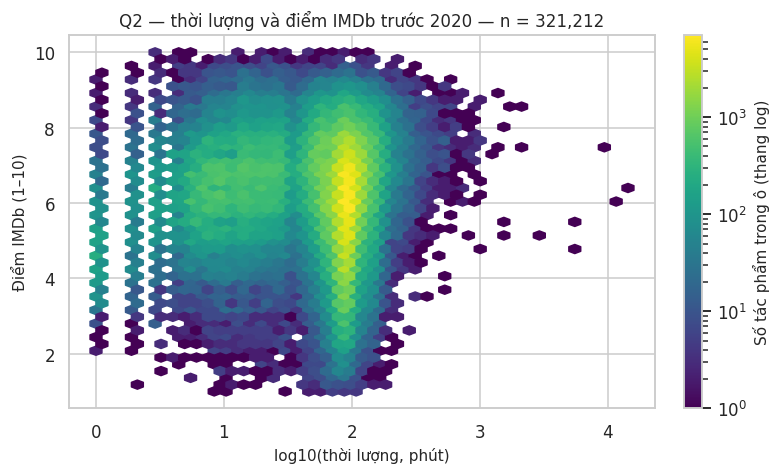

In [47]:
ml_runtime = ml_train.loc[ml_train.runtime.gt(0)]
display(pd.DataFrame([
    ['Trước 2020', len(ml_train), 0],
    ['Có thời lượng dương để vẽ quan hệ', len(ml_runtime), len(ml_train) - len(ml_runtime)],
], columns=['mẫu hiển thị', 'số tác phẩm', 'loại thêm']))
fig, ax = plt.subplots(figsize=(7, 4.2), layout='constrained')
hb = ax.hexbin(np.log10(ml_runtime.runtime), ml_runtime.averageRating,
               gridsize=45, mincnt=1, bins='log', cmap='viridis')
ax.set(title=f'Q2 — thời lượng và điểm IMDb trước 2020 — n = {len(ml_runtime):,}',
       xlabel='log10(thời lượng, phút)', ylabel='Điểm IMDb (1–10)')
fig.colorbar(hb, ax=ax, label='Số tác phẩm trong ô (thang log)')
plt.show()

Điểm trung vị theo thể loại dưới đây giúp xem một đầu vào phân loại có khác nhau về mức điểm hay không. Chỉ phần trước 2020 có nhãn thể loại được dùng. Phim có nhiều thể loại xuất hiện ở nhiều hàng.

In [48]:
ml_genres = ml_train[['id', 'averageRating', 'genre_list']].explode('genre_list').dropna(subset=['genre_list'])
ml_genre_profile = ml_genres.groupby('genre_list').agg(
    n=('id', 'size'), diem_trung_vi=('averageRating', 'median'))
display(ml_genre_profile.sort_values('n', ascending=False).head(8).round(3))

,n,diem_trung_vi
genre_list,,
Drama,121653,6.3
Comedy,79162,6.1
Documentary,48481,7.1
Romance,31550,6.2
Thriller,26506,5.7
Action,26431,5.8
Horror,23859,5.2
Animation,22461,6.5


Điểm và lượt chấm của hai nền tảng cùng `popularity` nằm ngoài đầu vào hồ sơ đã chọn. Các phép điền thời lượng, gom nhãn và mã hóa sẽ được học trong Pipeline trên tập train. Cross-validation cần giữ thứ tự thời gian của dữ liệu huấn luyện.

CSV chứa điểm ghi nhận ở lần trích xuất, chưa có lịch sử điểm theo thời gian. Câu Q2 vì vậy đánh giá khả năng ước lượng điểm trong bản dữ liệu hiện có từ hồ sơ phim. Một bài toán dự đoán điểm đúng vào mốc phát hành cần thêm dữ liệu được lưu tại mốc đó.

### 6.4. Q3 — Phim có ngày càng dài hơn không?

Mẫu gồm tác phẩm `Released` trong 1990–2024 có thể loại và thời lượng dương. Bảng báo trung vị, mốc 25%–75%, tỷ lệ dưới 60 phút và số tác phẩm trên 600 phút. Các tác phẩm ngắn và rất dài vẫn được giữ trong khảo sát ban đầu.

Ba giai đoạn đầu dài 10 năm, còn 2020–2024 dài 5 năm. Số phim theo giai đoạn dùng để đọc số mẫu sẵn có. Khoảng tô trong hình là nửa giữa phân phối thời lượng.

In [49]:
runtime_sample = question_frames['Q3']
runtime_by_period = runtime_sample.groupby('period', observed=True).agg(
    n=('id', 'size'), trung_vi=('runtime', 'median'),
    p25=('runtime', lambda values: values.quantile(.25)),
    p75=('runtime', lambda values: values.quantile(.75)),
    duoi_60_phut=('runtime', lambda values: 100 * values.lt(60).mean()),
    tren_600_phut=('runtime', lambda values: int(values.gt(600).sum())),
)
display(runtime_by_period.rename(columns={'n': 'Số tác phẩm', 'trung_vi': 'Trung vị (phút)',
    'p25': 'Mốc 25% (phút)', 'p75': 'Mốc 75% (phút)',
    'duoi_60_phut': 'Dưới 60 phút (%)', 'tren_600_phut': 'Trên 600 phút (số)'}).round(2))

,Số tác phẩm,Trung vị (phút),Mốc 25% (phút),Mốc 75% (phút),Dưới 60 phút (%),Trên 600 phút (số)
period,,,,,,
1990–1999,28725,91.0,75.0,102.0,18.69,8
2000–2009,50072,90.0,65.0,102.0,22.33,12
2010–2019,94457,86.0,52.0,99.0,28.04,15
2020–2024,36068,88.0,60.0,101.0,24.86,6


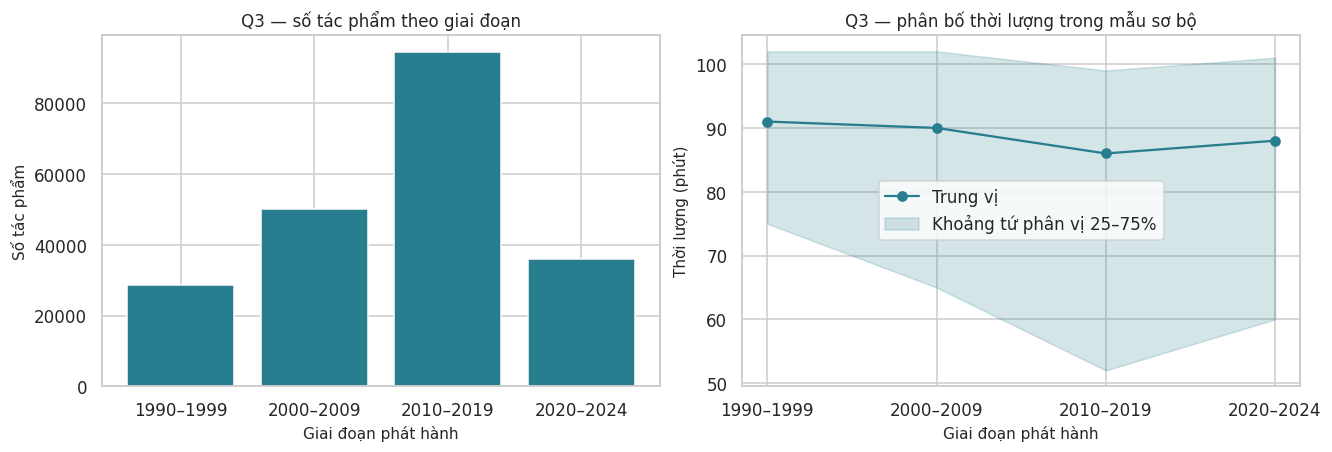

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
x = np.arange(len(runtime_by_period))
axes[0].bar(x, runtime_by_period['n'], color='#287e8e')
axes[0].set_xticks(x, runtime_by_period.index)
axes[0].set(title='Q3 — số tác phẩm theo giai đoạn', xlabel='Giai đoạn phát hành', ylabel='Số tác phẩm')
axes[1].plot(x, runtime_by_period.trung_vi, 'o-', color='#287e8e', label='Trung vị')
axes[1].fill_between(x, runtime_by_period.p25, runtime_by_period.p75, alpha=.2,
                     color='#287e8e', label='Khoảng tứ phân vị 25–75%')
axes[1].set_xticks(x, runtime_by_period.index)
axes[1].set(title='Q3 — phân bố thời lượng trong mẫu sơ bộ',
            xlabel='Giai đoạn phát hành', ylabel='Thời lượng (phút)')
axes[1].legend()
plt.show()

**Xem riêng trong từng thể loại**

Hai bảng dưới cùng thứ tự 6 thể loại nhiều mẫu nhất. Bảng số phim cho biết mỗi trung vị dựa trên bao nhiêu quan sát, còn bảng thời lượng giúp xem xu hướng có giống kết quả chung không. Ví dụ, thành phần phim tài liệu và phim truyện khác nhau có thể làm trung vị chung đổi theo thời gian.

In [51]:
runtime_genres = runtime_sample[['id', 'period', 'runtime', 'genre_list']].explode('genre_list')
top_runtime_genres = runtime_genres.genre_list.value_counts().head(6).index
runtime_grouped = runtime_genres.groupby(['genre_list', 'period'], observed=True).agg(
    n=('id', 'size'), trung_vi=('runtime', 'median'))
runtime_genre_counts = runtime_grouped['n'].unstack('period').reindex(top_runtime_genres)
runtime_genre_medians = runtime_grouped['trung_vi'].unstack('period').reindex(top_runtime_genres)
display(runtime_genre_counts.rename_axis(index='Thể loại — số tác phẩm', columns='Giai đoạn'))
display(runtime_genre_medians.rename_axis(index='Thể loại — trung vị phút', columns='Giai đoạn'))

Giai đoạn,1990–1999,2000–2009,2010–2019,2020–2024
Thể loại — số tác phẩm,,,,
Drama,12004,19467,36968,13824
Comedy,7197,12500,21788,7745
Documentary,3684,10668,21522,8475
Thriller,3393,5317,10314,4791
Horror,2160,4946,10406,4339
Romance,3225,5694,9134,3415


Giai đoạn,1990–1999,2000–2009,2010–2019,2020–2024
Thể loại — trung vị phút,,,,
Drama,96.0,95.0,90.0,92.0
Comedy,91.0,90.0,90.0,90.0
Documentary,60.0,72.0,76.0,80.0
Thriller,95.0,94.0,91.0,92.0
Horror,89.0,88.0,82.0,83.0
Romance,98.0,98.0,95.0,93.0


**Xem riêng trong từng ngôn ngữ gốc**

Bổ sung trung vị thời lượng bên cạnh số tác phẩm theo ngôn ngữ và giai đoạn. Bảng giữ 8 ngôn ngữ nhiều tác phẩm nhất trong mẫu Q3. `en`, `fr`, `es`, `de`, `ja`, `pt`, `ru`, `it` lần lượt là Anh, Pháp, Tây Ban Nha, Đức, Nhật, Bồ Đào Nha, Nga và Ý.

In [52]:
top_runtime_languages = runtime_sample.original_language.value_counts().head(8).index
language_counts = pd.crosstab(runtime_sample.original_language, runtime_sample.period).reindex(top_runtime_languages)
language_medians = runtime_sample.groupby(['original_language', 'period'], observed=True).runtime.median()
language_medians = language_medians.unstack('period').reindex(top_runtime_languages)
display(language_counts.rename_axis(index='Ngôn ngữ — số tác phẩm', columns='Giai đoạn'))
display(language_medians.rename_axis(index='Ngôn ngữ — trung vị phút', columns='Giai đoạn'))

Giai đoạn,1990–1999,2000–2009,2010–2019,2020–2024
Ngôn ngữ — số tác phẩm,,,,
en,16095,28680,51614,18893
fr,1550,2766,4960,2309
es,903,1971,4861,1830
de,1063,2075,3362,1182
ja,1308,2061,3173,842
pt,342,929,2257,840
ru,724,836,1533,632
it,652,858,1427,684


Giai đoạn,1990–1999,2000–2009,2010–2019,2020–2024
Ngôn ngữ — trung vị phút,,,,
en,90.0,86.0,82.0,85.0
fr,91.0,90.0,85.0,85.0
es,92.0,90.0,84.0,85.0
de,90.0,90.0,90.0,89.0
ja,87.5,95.0,96.0,103.0
pt,85.0,84.0,80.0,83.0
ru,88.0,94.0,87.0,90.0
it,95.0,96.0,90.0,92.0


**Phạm vi độ dài có làm thay đổi bức tranh không?**

Mốc 60 phút là một lựa chọn để thử độ nhạy về loại tác phẩm. Bảng đối chiếu mẫu thời lượng dương ban đầu với phần từ 60 phút trở lên, có số tác phẩm giữ lại và bị loại. Cách này giúp thấy ảnh hưởng của phim ngắn trước khi nhóm quyết định phạm vi phân tích Q3.

In [53]:
runtime_long = runtime_sample.loc[runtime_sample.runtime.ge(60)]
long_by_period = runtime_long.groupby('period', observed=True).runtime.agg(['size', 'median'])
runtime_sensitivity = pd.DataFrame({
    'Số phim thời lượng dương': runtime_by_period['n'],
    'Trung vị ban đầu (phút)': runtime_by_period.trung_vi,
    'Số phim từ 60 phút': long_by_period['size'],
    'Trung vị từ 60 phút': long_by_period['median'],
})
runtime_sensitivity['Số phim bị loại khi thêm mốc 60'] = (
    runtime_sensitivity['Số phim thời lượng dương'] - runtime_sensitivity['Số phim từ 60 phút'])
display(runtime_sensitivity.rename_axis('Giai đoạn'))

,Số phim thời lượng dương,Trung vị ban đầu (phút),Số phim từ 60 phút,Trung vị từ 60 phút,Số phim bị loại khi thêm mốc 60
Giai đoạn,,,,,
1990–1999,28725,91.0,23355,95.0,5370
2000–2009,50072,90.0,38889,93.0,11183
2010–2019,94457,86.0,67975,92.0,26482
2020–2024,36068,88.0,27100,93.0,8968


Trung vị chung ban đầu giảm từ 91 xuống 86 phút rồi lên 88 phút ở 2020–2024. Riêng phim tài liệu trong mẫu có trung vị tăng từ 60 lên 80 phút. Những mô tả này cho thấy cần xét thành phần thể loại và ngôn ngữ trước khi trả lời câu hỏi chung. Notebook 02 sẽ ước lượng khoảng tin cậy cho chênh lệch giữa các giai đoạn.

### 6.5. Q4 — Có đủ phim để so doanh thu theo thể loại và ngân sách không?

Mẫu Q4 gồm tác phẩm `Released` trong 1990–2024 có thể loại và cả ngân sách lẫn doanh thu dương. Các bảng tiếp theo dùng để kiểm tra số mẫu và độ rộng ngân sách trước khi chọn nhóm so sánh.

Doanh thu và ngân sách bằng 1 vẫn nằm trong mẫu kiểm tra này. Việc xác minh nguồn, tiền tệ, phạm vi doanh thu và các giá trị đáng nghi được ghi là bước cần hoàn tất trước khi diễn giải kết quả tài chính.

In [54]:
finance = question_frames['Q4'].copy()
finance_log = np.log10(finance[['budget', 'revenue']])
finance_period_profile = finance.groupby('period', observed=True).agg(
    n=('id', 'size'), en_pct=('original_language', lambda values: 100 * values.eq('en').mean()))
display(finance_period_profile.rename(columns={'n': 'Số tác phẩm', 'en_pct': 'Ngôn ngữ gốc en (%)'}).rename_axis('Giai đoạn').round(2))
finance_small = pd.Series({
    'Ngân sách bằng 1': int(finance.budget.eq(1).sum()),
    'Doanh thu bằng 1': int(finance.revenue.eq(1).sum()),
    'Ngân sách hoặc doanh thu bằng 1': int((finance.budget.eq(1) | finance.revenue.eq(1)).sum()),
})
display(finance_small.to_frame('Số tác phẩm cần đối chiếu'))

,Số tác phẩm,Ngôn ngữ gốc en (%)
Giai đoạn,,
1990–1999,1419,90.77
2000–2009,2676,75.60
2010–2019,3358,63.34
2020–2024,596,69.13


,Số tác phẩm cần đối chiếu
Ngân sách bằng 1,18
Doanh thu bằng 1,15
Ngân sách hoặc doanh thu bằng 1,28


**Ngân sách thấp, vừa, cao đang rộng đến đâu?**

Cách chia thử dùng thứ hạng ngân sách trong mỗi giai đoạn thành ba phần gần bằng nhau. Các phim cùng ngân sách được giữ cùng nhóm, nên số phim mỗi phần có thể khác nhau. Bảng báo cả nhỏ nhất, trung vị và lớn nhất để thấy độ rộng.

Nhãn thấp, vừa, cao mang nghĩa tương đối trong từng giai đoạn. Những khoảng quá rộng cần được chia hẹp hơn hoặc kiểm soát ngân sách liên tục khi phân tích Q4. Cùng tên nhóm ở hai giai đoạn cũng có thể ứng với khoảng tiền khác nhau.

In [55]:
budget_rank = finance.groupby('period', observed=True).budget.rank(method='average', pct=True)
finance['budget_group'] = pd.cut(budget_rank, bins=[0, 1/3, 2/3, 1],
    labels=['Thấp', 'Vừa', 'Cao'], include_lowest=True)
budget_ranges = finance.groupby(['period', 'budget_group'], observed=True).agg(
    n=('id', 'size'), budget_min=('budget', 'min'), budget_median=('budget', 'median'),
    budget_max=('budget', 'max'))
display(budget_ranges.rename(columns={'n': 'Số tác phẩm', 'budget_min': 'Ngân sách nhỏ nhất',
    'budget_median': 'Ngân sách trung vị', 'budget_max': 'Ngân sách lớn nhất'})
    .rename_axis(index=['Giai đoạn', 'Nhóm ngân sách']).style.format('{:,.0f}'))

**Mỗi thể loại còn bao nhiêu phim sau khi chia nhóm?**

Bảng dưới chia riêng từng giai đoạn để tránh một bảng quá rộng. Mỗi ô là số tác phẩm của một thể loại trong nhóm ngân sách tương ứng. Một tác phẩm có thể xuất hiện ở nhiều thể loại, nên tổng các hàng có thể đếm lại cùng phim. Những ô ít phim cần được lưu ý khi tính trung vị và khoảng tin cậy.

In [56]:
finance_genres = finance[['id', 'period', 'budget_group', 'genre_list']].explode('genre_list')
top_finance_genres = finance_genres.genre_list.value_counts().head(8).index
finance_genre_period_counts = pd.crosstab(finance_genres.genre_list, finance_genres.period).reindex(top_finance_genres)
finance_group_counts = finance_genres.groupby(['genre_list', 'period', 'budget_group'], observed=True).id.nunique()
finance_group_counts = finance_group_counts.unstack(['period', 'budget_group']).reindex(top_finance_genres).fillna(0).astype(int)
for period in period_labels:
    display(Markdown(f'**{period} — số tác phẩm theo thể loại và ngân sách**'))
    display(finance_group_counts[period].rename_axis(index='Thể loại', columns='Nhóm ngân sách'))

**1990–1999 — số tác phẩm theo thể loại và ngân sách**

Nhóm ngân sách,Thấp,Vừa,Cao
Thể loại,,,
Drama,215,224,211
Comedy,183,229,152
Action,75,96,171
Thriller,90,110,158
Romance,93,106,76
Adventure,25,58,123
Crime,85,92,93
Horror,62,45,34


**2000–2009 — số tác phẩm theo thể loại và ngân sách**

Nhóm ngân sách,Thấp,Vừa,Cao
Thể loại,,,
Drama,522,471,329
Comedy,310,341,350
Action,130,176,311
Thriller,155,240,275
Romance,186,215,172
Adventure,60,85,267
Crime,124,143,150
Horror,110,114,61


**2010–2019 — số tác phẩm theo thể loại và ngân sách**

Nhóm ngân sách,Thấp,Vừa,Cao
Thể loại,,,
Drama,555,600,423
Comedy,412,342,406
Action,175,226,479
Thriller,238,299,285
Romance,196,190,134
Adventure,67,108,366
Crime,117,148,175
Horror,144,139,69


**2020–2024 — số tác phẩm theo thể loại và ngân sách**

Nhóm ngân sách,Thấp,Vừa,Cao
Thể loại,,,
Drama,85,90,54
Comedy,47,59,67
Action,23,56,100
Thriller,45,61,50
Romance,21,29,11
Adventure,16,35,79
Crime,12,27,31
Horror,47,45,16


Hình trái cho thấy ngân sách–doanh thu trong mẫu tài chính dương. Hình phải cho biết số tác phẩm của 8 thể loại nhiều mẫu nhất trong mỗi giai đoạn. Hình về số lượng giúp chọn các nhóm khả thi cho phân tích tiếp theo.

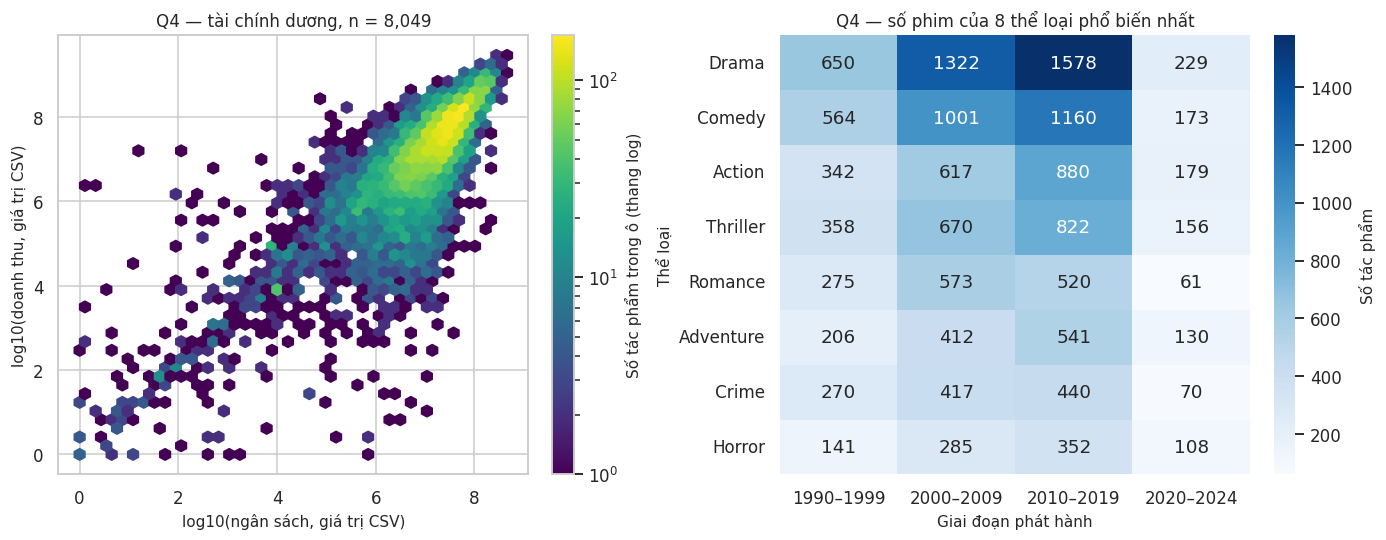

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), layout='constrained')
hb = axes[0].hexbin(finance_log.budget, finance_log.revenue, gridsize=40,
                    mincnt=1, bins='log', cmap='viridis')
axes[0].set(title=f'Q4 — tài chính dương, n = {len(finance):,}',
            xlabel='log10(ngân sách, giá trị CSV)', ylabel='log10(doanh thu, giá trị CSV)')
fig.colorbar(hb, ax=axes[0], label='Số tác phẩm trong ô (thang log)')
sns.heatmap(finance_genre_period_counts, annot=True, fmt='d', cmap='Blues',
            ax=axes[1], cbar_kws={'label': 'Số tác phẩm'})
axes[1].set(title='Q4 — số phim của 8 thể loại phổ biến nhất',
            xlabel='Giai đoạn phát hành', ylabel='Thể loại')
plt.show()

In [58]:
smallest_group = int(finance_group_counts.where(finance_group_counts.gt(0)).min().min())
display(Markdown(f'Q4 giữ **{len(finance):,} tác phẩm**, chiếm **{len(finance)/n:.2%}** CSV. '
    f'Tỷ lệ ngôn ngữ gốc en là **{finance.original_language.eq("en").mean():.2%}**. '
    f'Ô có quan sát nhỏ nhất trong các thể loại hiển thị chỉ có **{smallest_group} tác phẩm**. '
    'Ví dụ, nhóm ngân sách cao của 2020–2024 có khoảng rộng từ 26 triệu đến 460 triệu theo giá trị CSV. '
    'Các nhóm này còn cần thu hẹp để so những phim có ngân sách tương đồng.'))

Q4 giữ **8,049 tác phẩm**, chiếm **1.81%** CSV. Tỷ lệ ngôn ngữ gốc en là **72.68%**. Ô có quan sát nhỏ nhất trong các thể loại hiển thị chỉ có **11 tác phẩm**. Ví dụ, nhóm ngân sách cao của 2020–2024 có khoảng rộng từ 26 triệu đến 460 triệu theo giá trị CSV. Các nhóm này còn cần thu hẹp để so những phim có ngân sách tương đồng.

### 6.6. Tương quan giữa các cột số trên cùng một mẫu

Heatmap dùng mẫu Q4 rồi giữ thêm thời lượng dương, hai điểm hợp lệ, lượt chấm dương ở cả hai bên và đủ tám giá trị hữu hạn. Bảng lọc cho biết mẫu thay đổi ra sao. Mọi hệ số trong hình dùng cùng một nhóm tác phẩm.

Spearman mô tả mức đi cùng nhau theo thứ hạng. Hệ số dương gần 1 nghĩa là tác phẩm có giá trị cao ở cột này thường cũng cao ở cột kia. Hệ số mô tả mẫu tài chính đầy đủ đã lọc. Quan hệ ở toàn bộ CSV hoặc mẫu Q2 cần được xét trên mẫu tương ứng.

In [59]:
corr_cols = ['budget', 'revenue', 'runtime', 'vote_average', 'averageRating',
             'vote_count', 'numVotes', 'popularity']
corr_index = question_frames['Q4'].index
corr_candidates = movies.loc[corr_index, corr_cols]
corr_selected = pd.Series(True, index=corr_index)
corr_steps = [
    ('Thời lượng dương', corr_candidates.runtime.gt(0)),
    ('Điểm hợp lệ và có lượt chấm ở cả hai bên',
     corr_candidates.vote_average.between(0, 10)
     & corr_candidates.averageRating.between(1, 10)
     & corr_candidates.vote_count.gt(0) & corr_candidates.numVotes.gt(0)),
    ('Đủ tám giá trị hữu hạn', np.isfinite(corr_candidates).all(axis=1)),
]
corr_flow_rows = [['Mẫu Q4', len(corr_index), 0]]
for label, condition in corr_steps:
    before = int(corr_selected.sum())
    corr_selected &= condition
    after = int(corr_selected.sum())
    corr_flow_rows.append([label, after, before - after])
corr_flow = pd.DataFrame(corr_flow_rows, columns=['điều kiện thêm vào', 'số tác phẩm', 'loại thêm'])
display(corr_flow)

,điều kiện thêm vào,số tác phẩm,loại thêm
0,Mẫu Q4,8049,0
1,Thời lượng dương,7979,70
2,Điểm hợp lệ và có lượt chấm ở cả hai bên,7779,200
3,Đủ tám giá trị hữu hạn,7779,0


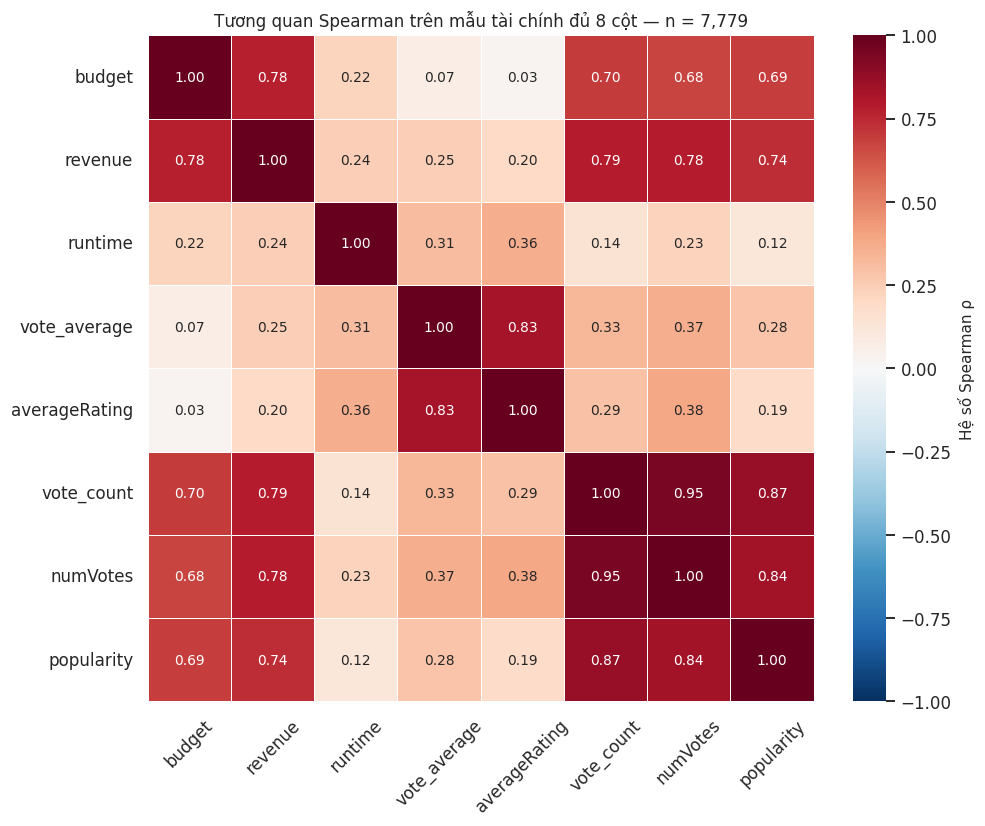

In [60]:
correlation_sample = corr_candidates.loc[corr_selected]
corr_matrix = correlation_sample.corr(method='spearman')
fig, ax = plt.subplots(figsize=(9, 7.4), layout='constrained')
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdBu_r',
            vmin=-1, vmax=1, center=0, square=True, linewidths=.4,
            ax=ax, cbar_kws={'label': 'Hệ số Spearman ρ'}, annot_kws={'fontsize': 9})
ax.set(title=f'Tương quan Spearman trên mẫu tài chính đủ 8 cột — n = {len(correlation_sample):,}')
ax.tick_params(axis='x', labelrotation=45)
ax.tick_params(axis='y', labelrotation=0)
plt.show()

In [61]:
display(Markdown(
    f'Heatmap dùng **{len(correlation_sample):,} tác phẩm**, '
    f'tương đương **{len(correlation_sample)/n:.2%} toàn bộ CSV**. '
    f'Spearman của ngân sách–doanh thu là **{corr_matrix.loc["budget", "revenue"]:.3f}**, '
    f'của lượt chấm TMDB–IMDb là **{corr_matrix.loc["vote_count", "numVotes"]:.3f}** '
    'trong mẫu này. Các hệ số thuộc cùng một mẫu đã lọc. '
    'Những bảng theo từng câu hỏi bên dưới có thể dùng mẫu khác theo điều kiện riêng.'
))

Heatmap dùng **7,779 tác phẩm**, tương đương **1.75% toàn bộ CSV**. Spearman của ngân sách–doanh thu là **0.775**, của lượt chấm TMDB–IMDb là **0.953** trong mẫu này. Các hệ số thuộc cùng một mẫu đã lọc. Những bảng theo từng câu hỏi bên dưới có thể dùng mẫu khác theo điều kiện riêng.

## 7. Tóm tắt khám phá và hướng tiền xử lý

### 7.1. Năm quan sát chính

Các số dưới đây được tính từ lần chạy notebook. Phạm vi mỗi quan sát gắn với mẫu và điều kiện đã ghi ở mục 6.

In [62]:
notes = [
    f'**Mã phim và dòng lặp.** CSV có {n:,} dòng, {movies.shape[1]} cột, '
    f'{int(movies.id.duplicated().sum()):,} dòng lặp sau lần đầu theo TMDb và '
    f'{int(movies.tconst.duplicated().sum()):,} theo IMDb. Mẫu hai mã chỉ xuất hiện một lần còn {len(analysis_base):,} dòng.',
    f'**Ngày và thể loại.** Thiếu ngày ở {int(missing.release_date.sum()):,} dòng ({missing.release_date.mean():.2%}), '
    f'thiếu thể loại ở {int(missing.genres.sum()):,} dòng ({missing.genres.mean():.2%}). '
    f'{joint_missing:,} dòng thiếu cả hai. Sau khi bỏ nhãn lặp trong mỗi dòng, có {int(genre_count.gt(1).sum()):,} dòng đa thể loại.',
    f'**Điểm và lượt chấm.** Q1 giữ {int(rating_sensitivity.loc[10, "n"]):,} tác phẩm ở ngưỡng 10 lượt, '
    f'còn {int(rating_sensitivity.loc[100, "n"]):,} ở ngưỡng 100. Khoảng cách điểm tuyệt đối trung bình lần lượt là '
    f'{rating_sensitivity.loc[10, "|Δ| trung bình"]:.3f} và {rating_sensitivity.loc[100, "|Δ| trung bình"]:.3f} điểm. '
    f'Q2 có {len(ml_train):,} tác phẩm trước 2020 và {len(ml_test):,} tác phẩm 2020–2024 sau khi lọc Released.',
    f'**Thời lượng.** Q3 có {len(runtime_sample):,} tác phẩm và {runtime_sample.runtime.lt(60).mean():.2%} '
    'ngắn hơn 60 phút. Trung vị qua bốn giai đoạn là 91, 90, 86 và 88 phút. '
    'Nhóm thể loại và ngôn ngữ có thể cho xu hướng khác kết quả chung.',
    f'**Tài chính.** Ngân sách bằng 0 ở {movies.budget.eq(0).mean():.2%} CSV và doanh thu bằng 0 ở '
    f'{movies.revenue.eq(0).mean():.2%}. Q4 còn {len(finance):,} tác phẩm ({len(finance)/n:.2%} CSV), '
    f'trong đó {finance.original_language.eq("en").mean():.2%} có ngôn ngữ gốc en. '
    'Phạm vi tài chính, tiền tệ và nhóm ngân sách còn cần xác minh trước khi so doanh thu.',
]
display(Markdown('\n\n'.join(f'{i}. {note}' for i, note in enumerate(notes, 1))))

1. **Mã phim và dòng lặp.** CSV có 443,656 dòng, 29 cột, 13,894 dòng lặp sau lần đầu theo TMDb và 16,995 theo IMDb. Mẫu hai mã chỉ xuất hiện một lần còn 425,189 dòng.

2. **Ngày và thể loại.** Thiếu ngày ở 25,363 dòng (5.72%), thiếu thể loại ở 83,813 dòng (18.89%). 20,069 dòng thiếu cả hai. Sau khi bỏ nhãn lặp trong mỗi dòng, có 171,180 dòng đa thể loại.

3. **Điểm và lượt chấm.** Q1 giữ 55,418 tác phẩm ở ngưỡng 10 lượt, còn 14,559 ở ngưỡng 100. Khoảng cách điểm tuyệt đối trung bình lần lượt là 0.561 và 0.398 điểm. Q2 có 363,367 tác phẩm trước 2020 và 43,911 tác phẩm 2020–2024 sau khi lọc Released.

4. **Thời lượng.** Q3 có 209,322 tác phẩm và 24.84% ngắn hơn 60 phút. Trung vị qua bốn giai đoạn là 91, 90, 86 và 88 phút. Nhóm thể loại và ngôn ngữ có thể cho xu hướng khác kết quả chung.

5. **Tài chính.** Ngân sách bằng 0 ở 93.16% CSV và doanh thu bằng 0 ở 96.25%. Q4 còn 8,049 tác phẩm (1.81% CSV), trong đó 72.68% có ngôn ngữ gốc en. Phạm vi tài chính, tiền tệ và nhóm ngân sách còn cần xác minh trước khi so doanh thu.

### 7.2. Vấn đề chất lượng và việc cần làm tiếp

Các vấn đề chính gồm mã lặp, ô thiếu ngày và thể loại, số 0 tài chính/thời lượng, điểm và lượt chấm chưa nhất quán, cùng ngày phát hành cần đối chiếu trạng thái. Cực trị được xem cùng loại tác phẩm và nguồn xác minh.

| Câu | Hướng tiền xử lý và phân tích tiếp |
| --- | --- |
| Chung | Dùng mẫu hai mã chỉ xuất hiện một lần và báo số dòng ở mỗi bước. Nếu gộp nhóm mã lặp để giữ thêm phim, cần xử lý xung đột thông tin và kiểm tra độ nhạy. |
| Q1 | Giữ điểm đúng thang và ngưỡng 10/100 lượt. Báo riêng mẫu chung và mẫu có thể loại. So chênh lệch trong các nhóm, ước lượng khoảng tin cậy bằng bootstrap theo tác phẩm trong notebook 02. |
| Q2 | Dùng hồ sơ và điểm IMDb đúng phạm vi. Tạo cột đánh dấu thời lượng thiếu, xử lý thể loại và nhãn mới trong Pipeline học trên train. So baseline và ít nhất hai mô hình bằng MAE, cross-validation theo thời gian, đánh giá test một lần và phân tích lỗi trong notebook 03. |
| Q3 | Giữ thời lượng dương, xác định phạm vi tác phẩm và đối chiếu cực trị. So xu hướng theo thể loại/ngôn ngữ, thử mốc độ dài, ước lượng độ bất định theo tác phẩm trong notebook 02. |
| Q4 | Xác minh tiền tệ và phạm vi doanh thu, xem các giá trị bằng 1, kiểm tra ảnh hưởng của mẫu chỉ có tài chính dương. Thu hẹp nhóm ngân sách hoặc kiểm soát ngân sách liên tục, báo số phim từng nhóm và thử các lựa chọn khác trong notebook 02. |

Những mẫu hình cần theo dõi gồm khoảng cách điểm thay đổi khi tăng lượt chấm, trung vị thời lượng theo nhóm khác xu hướng chung, và số phim tài chính giảm mạnh khi chia nhiều chiều. Các kết luận được đặt trong phạm vi mẫu tương ứng.

### 7.3. Kiểm tra lần chạy

Ô cuối xác nhận nguồn CSV giữ nguyên SHA-256, số dòng qua từng bộ lọc khớp nhau và các bảng theo thể loại dùng nhãn đã bỏ lặp.

In [63]:
# Kiểm tra tính nhất quán của nguồn, các bộ lọc và những bảng dùng để diễn giải.
assert file_sha256(RAW_PATH) == raw_sha256
assert wrong_width_records == 0
assert csv_records - empty_records == n
assert missing.shape == movies.shape
assert missing_table['số thiếu'].between(0, n).all()
assert analysis_base.id.is_unique and analysis_base.tconst.is_unique
for question, mask in question_masks.items():
    assert question_frames[question].index.equals(movies.index[mask])
    assert question_frames[question].index.isin(analysis_base.index).all()
    rows = sample_flow.loc[sample_flow['câu'].eq(question)]
    assert rows['số dòng còn lại'].is_monotonic_decreasing
    assert rows['loại ở bước này'].ge(0).all()
    assert len(analysis_base) - rows['loại ở bước này'].sum() == len(question_frames[question])
assert rating_sensitivity.loc[10, 'n'] == len(q1)
assert rating_sensitivity['n'].is_monotonic_decreasing
assert q1.release_year.between(1990, 2024).all()
assert len(ml_train) + len(ml_test) == len(ml_scope)
assert ml_train.index.intersection(ml_test.index).empty
assert ml_train.release_year.lt(2020).all()
assert ml_test.release_year.between(2020, 2024).all()
assert runtime_sample.runtime.gt(0).all()
assert runtime_by_period['n'].sum() == len(runtime_sample)
assert finance[['budget', 'revenue']].gt(0).all().all()
assert finance.budget_group.notna().all()
assert budget_ranges['n'].sum() == len(finance)
assert finance_period_profile['n'].sum() == len(finance)
assert outlier_audit['số giá trị ngoài ngưỡng IQR'].between(0, outlier_audit['n']).all()
assert outlier_audit['số giá trị có |z| > 3'].between(0, outlier_audit['số giá trị tính được z-score']).all()
assert outlier_audit['số giá trị tính được z-score'].between(0, outlier_audit['n']).all()
assert corr_matrix.shape == (8, 8)
assert correlation_sample.index.is_unique
assert correlation_sample.index.isin(question_frames['Q4'].index).all()
assert np.isfinite(correlation_sample).all().all()
assert corr_flow['số tác phẩm'].is_monotonic_decreasing
assert corr_flow['số tác phẩm'].iloc[0] - corr_flow['loại thêm'].sum() == len(correlation_sample)
assert np.allclose(corr_matrix, corr_matrix.T)
assert np.allclose(np.diag(corr_matrix), 1)
assert corr_matrix.abs().le(1).all().all()
assert len(notes) == 5
print('Đã kiểm tra nguồn và các mẫu Q1–Q4. SHA-256 CSV khớp trước, sau chạy.')
assert genre_count.gt(1).sum() == 171180
assert genre_duplicate_tokens.sum() == 95
assert genre_lists.map(lambda labels: len(labels) == len(set(labels))).all()
assert genre_tokens.value_counts().equals(genre_counts)
assert len(analysis_base) == 425189
assert question_sizes['Q1'] == 55418
assert question_sizes['Q3'] == 209322
assert question_sizes['Q4'] == 8049
for frame in question_frames.values():
    assert frame.status.eq('Released').all()
assert sum(len(labels) for labels in q1.loc[q1.genre_list.map(len).gt(0), 'genre_list']) == len(q1_genre_source)
assert language_counts.sum().sum() == runtime_sample.original_language.isin(top_runtime_languages).sum()
assert runtime_sensitivity['Số phim bị loại khi thêm mốc 60'].ge(0).all()
assert missing.sum().equals(missing_table['số thiếu'].reindex(missing.columns))
assert 'budget' not in question_columns['Q2']
assert 'vote_average' not in question_columns['Q2']
print('Đã kiểm tra thêm số thể loại khác nhau, trạng thái phát hành và các bảng mới.')

Đã kiểm tra nguồn và các mẫu Q1–Q4. SHA-256 CSV khớp trước, sau chạy.
Đã kiểm tra thêm số thể loại khác nhau, trạng thái phát hành và các bảng mới.
